# From the Mutual Fund Theorem to the Security Market Line
### Does the theory survive real data?

**FE 5108 Portfolio Theory and Investments, Group project**

*Risk Management Institute, National University of Singapore*

---

This notebook is the report and the evidence together. Every table and figure is
generated from the committed data under `data/`.

**Contents**

1. [Executive summary](#1-executive-summary)
2. [Data and methodology](#2-data-and-methodology)
3. [Stage 1: portfolio choice and estimation error](#3-stage-1-portfolio-choice-and-estimation-error)
4. [Stage 2: the CAPM and the empirical SML](#4-stage-2-the-capm-and-the-empirical-sml)
5. [Stage 3: factors](#5-stage-3-factors)
6. [Robustness: the market proxy](#6-robustness-the-market-proxy)
7. [Stage 4: the memo to the investment committee](#7-stage-4-the-memo-to-the-investment-committee)
8. [Appendix](#appendix)


## 1. Executive summary

We estimate mean variance portfolios and test the CAPM on 30 US securities over
119 months, then repeat on 29 Singapore names. The theory organises risk well. It
does not build a portfolio well.

**Portfolio choice (Stage 1).** The tangency portfolio fails first. In the US it
shorts one stock by 280% and its weights correlate at only 0.35 across the two
halves of the sample; Singapore is worse, at -0.01. A no-short constraint and
shrinkage cut the largest US position from 280% to 11% and gross leverage from
16x to 1.3x, and out of sample the shrunk long-only version earns a Sharpe of 0.95
against 0.69 for the raw solution.

**The CAPM (Stage 2).** The security market line also misses: the US slope is
0.016 against a theoretical 0.019 and the fitted intercept is 0.000, while
Singapore's line is almost flat, a slope of 0.001 against 0.011 with a positive
intercept of 0.006.
The alphas are kinder. The US joint test cannot reject zero (GRS p = 0.47), with
2 of 30 assets past |t| > 2, about the count expected by chance; Singapore is
marginal (p = 0.09) with 3 of 29 significant.

**Factors (Stage 3).** We build four factors - size, momentum, low volatility and
short-term reversal - from the universes themselves. In the US they change
little, where nothing was badly wrong to begin with: mean |alpha| is 0.45% a
month under the CAPM and 0.52% with all four, and no joint test rejects (GRS p
falls from 0.46 to 0.27). In Singapore they do not shrink the alphas either -
mean |alpha| rises from 0.63% to 0.71% and eight alphas are significant under the
full set against five under the CAPM - but they sharpen the joint test, from a
marginal GRS p of 0.07 to 0.004, because they shrink the residual covariance
faster than the alphas. Factors add explanatory power without explaining the
anomaly away. On sixty years of Ken French's
ten US industries, where nothing is missing for having failed, industry momentum
is priced (3.8% a year, t = 2.2, alphas significant against the CAPM and FF3), yet
over our 119 months the same rule has t = 1.0, so the US null is a lack of power,
and at 50 basis points a trade the premium does not survive costs.

**Judgment (Stage 4).** The verdict moves with the market proxy, which lifts the
US GRS p from 0.47 to 0.19 and shifts the average beta by 0.17 on the same assets
- a reminder that a CAPM test is a joint test of the model and the proxy. We would
hold the value-weighted index, or a shrunk long-only tilt, not the raw tangency
portfolio.


## 2. Data and methodology

We use 30 US securities (21 large capitalisation companies, 9 sector ETFs) over
119 months, October 2016 to August 2026, and repeat the CAPM on 29 Singapore
listings. US returns are month end Yahoo prices adjusted for splits and dividends;
Singapore returns are rebuilt by us, for the reasons below.
Tickers below 90 clean observations are dropped, and a month is kept only when
every asset has a price, so the panel is balanced and the covariance matrix is
invertible.

The US risk free rate is the Fama and French one month Treasury bill. Singapore
uses the MAS compounded SORA index, converted to monthly as the ratio of
consecutive month end levels. The market proxy defaults to a value weighted
composite of the same universe, replaced in Section 6 by the Fama and French
factor. For Stage 3 we use Ken French's market factor as the US benchmark and
build size, momentum, low-volatility and reversal long-short spreads from the
same universe for both markets.

Every return is a total return in the asset's **local currency**: the US series
is in USD and the Singapore series in SGD (the three Singapore listings quoted in
US dollars - DFI Retail, Hongkong Land and Jardine Matheson - are converted at the
month end USD/SGD rate), and we do not convert to a common currency. The two markets are therefore compared on their own terms; an SGD
investor holding the US names would also bear the USD/SGD move, which is outside
this analysis.

**Cleaning the Singapore data.** We checked every Yahoo series against Yahoo's raw
closes and dividends, SGX's own unadjusted prices and SGX's corporate-action
records. The US series needed no correction; five Singapore series did. Yahoo
adjusted ThaiBev's dividends using the baht amount as if it were Singapore
dollars, so its adjusted price compounds 287 times over the decade while a holder
actually lost a third; it under-counts Jardine C&C's dividends since 2020 the same
way in US dollars; and at the three large spin-offs - Sembcorp Industries (2020),
Yangzijiang (2022) and Keppel (2023) - it shows ex-date jumps of 13% to 22% where
shareholders gained 3% to 10%, after inflating their earlier dividend yields up to
twofold. We therefore rebuild each Singapore return from Yahoo's daily close plus
cash dividends, put dividends paid before a distribution in specie on the same
price basis, and value each spin-off at the distributed shares' SGX price. Market
caps use SGX's unadjusted price (Yahoo's halved Sembcorp's before the demerger)
with two share-count glitches overridden. Every correction and its source is in
`data/corporate_actions_sg.csv`, and `data/cleaning_report_sg.txt` lists what each
one changed.

Three limitations matter. First, **survivorship bias**: both universes use
today's members carried back to 2016, so failed or delisted firms are missing.
This biases average returns and alphas **upward** - the Stage 1 means, the Stage 2
and 3 alpha estimates and the fitted SML all look better than a live investor's
experience - and it understates the tail the optimiser would have faced. Second,
delistings are absent rather than modelled, so no return is truncated at a
bankruptcy. Third, early Yahoo share counts are incomplete for a few names, so a
handful of market caps in the point-in-time value weights are approximations.


**Exhibit 1. The sample.** What the two universes cover.

**Takeaway.** Both panels are balanced, ten-year monthly samples - 119 months
from October 2016 to August 2026, 30 US names (21 mega-caps plus 9 sector ETFs)
and 29 Singapore listings. Because every surviving asset has a price in every
month, the covariance matrix is invertible and every cross-sectional regression
runs on a common window, so no test is quietly computed on a different sample
from its neighbour.


In [1]:
import base64
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display

from goldman import viz
from goldman.analysis import run_capm_analysis, run_portfolio_analysis
from goldman.config import ensure_outputs_dir, get_universe
from goldman.data import load_ff3, load_returns, load_value_weights, risk_free_series

# Figure display config: show every exhibit centred at a fixed pixel width.
# JupyterLab and VS Code both ignore the width metadata IPython attaches to
# image/png output, so render an HTML <img> with an explicit width instead.
FIGURE_WIDTH = 1000


def Image(filename=None, *, width=FIGURE_WIDTH, alt="", **kwargs):
    """Render a PNG as a centred HTML image of a fixed pixel width."""
    encoded = base64.b64encode(Path(filename).read_bytes()).decode("ascii")
    return HTML(
        f'<div style="text-align:center">'
        f'<img src="data:image/png;base64,{encoded}" width="{width}" alt="{alt}">'
        f"</div>"
    )

# The Fama and French market factor is published with a one month lag, so the
# Roll check in section 6 estimates on the sample the two proxies share.
warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 120)

UNIVERSES = ["us", "sg"]
PRIMARY = "us"
OUTPUT_DIR = ensure_outputs_dir()

RETURNS = {u: load_returns(universe=u) for u in UNIVERSES}

sample = pd.DataFrame(
    {
        u: {
            "currency": get_universe(u).currency,
            "assets": RETURNS[u].shape[1],
            "months": RETURNS[u].shape[0],
            "start": f"{RETURNS[u].index[0]:%Y-%m}",
            "end": f"{RETURNS[u].index[-1]:%Y-%m}",
        }
        for u in UNIVERSES
    }
).T
sample

,currency,assets,months,start,end
us,USD,30,119,2016-10,2026-08
sg,SGD,29,119,2016-10,2026-08


**Exhibit 1b. What the Singapore cleaning changed.** Growth of one dollar over the
sample in Yahoo's adjusted close and in our rebuilt series, local currency, for the
five corrected names.

**Takeaway.** None of the errors is small. In Yahoo's data ThaiBev compounds 287
times; in reality its holders lost a third. Each spin-off leaves one month
mis-stated by 6 to 13 percentage points - on its own enough to shift the stock's
average return by 0.6 to 1.4 percent a year, and it sits inside the momentum
signal for the next eleven months. Every Singapore result below uses the rebuilt
series.

In [2]:
from goldman.data import build_sg_clean

CORRECTED = {
    "Y92.SI": "ThaiBev: baht dividends read as SGD",
    "U96.SI": "Sembcorp Ind: Sembcorp Marine demerger, 2020-09",
    "BS6.SI": "Yangzijiang: financial arm spin-off, 2022-04",
    "BN4.SI": "Keppel: Sembcorp Marine distribution, 2023-02",
    "C07.SI": "Jardine C&C: US-dollar dividends read as SGD",
}
cleaning = build_sg_clean().summary.loc[list(CORRECTED)]
pd.DataFrame(
    {
        "problem": pd.Series(CORRECTED),
        "Yahoo growth": cleaning["growth Yahoo adj (local)"],
        "rebuilt growth": cleaning["growth clean (local)"],
        "largest monthly gap (return)": cleaning["max monthly gap"],
    }
).round(3)

,problem,Yahoo growth,rebuilt growth,largest monthly gap (return)
Y92.SI,ThaiBev: baht dividends read as SGD,286.683,0.665,1.591
U96.SI,"Sembcorp Ind: Sembcorp Marine demerger, 2020-09",6.338,5.333,0.134
BS6.SI,"Yangzijiang: financial arm spin-off, 2022-04",20.830,16.184,0.101
BN4.SI,"Keppel: Sembcorp Marine distribution, 2023-02",5.729,4.743,0.060
C07.SI,Jardine C&C: US-dollar dividends read as SGD,0.886,0.937,0.010


**Exhibit 2. Correlation structure.** How the assets move together.

**Takeaway.** Correlations are positive and mostly moderate, clustering the
mega-caps and sector ETFs into a single equity block. That is the near-collinearity
the mean-variance optimiser must invert: when many assets move together, small
errors in the estimated covariances compound through the inverse, which is where
Stage 1's extreme weights come from.



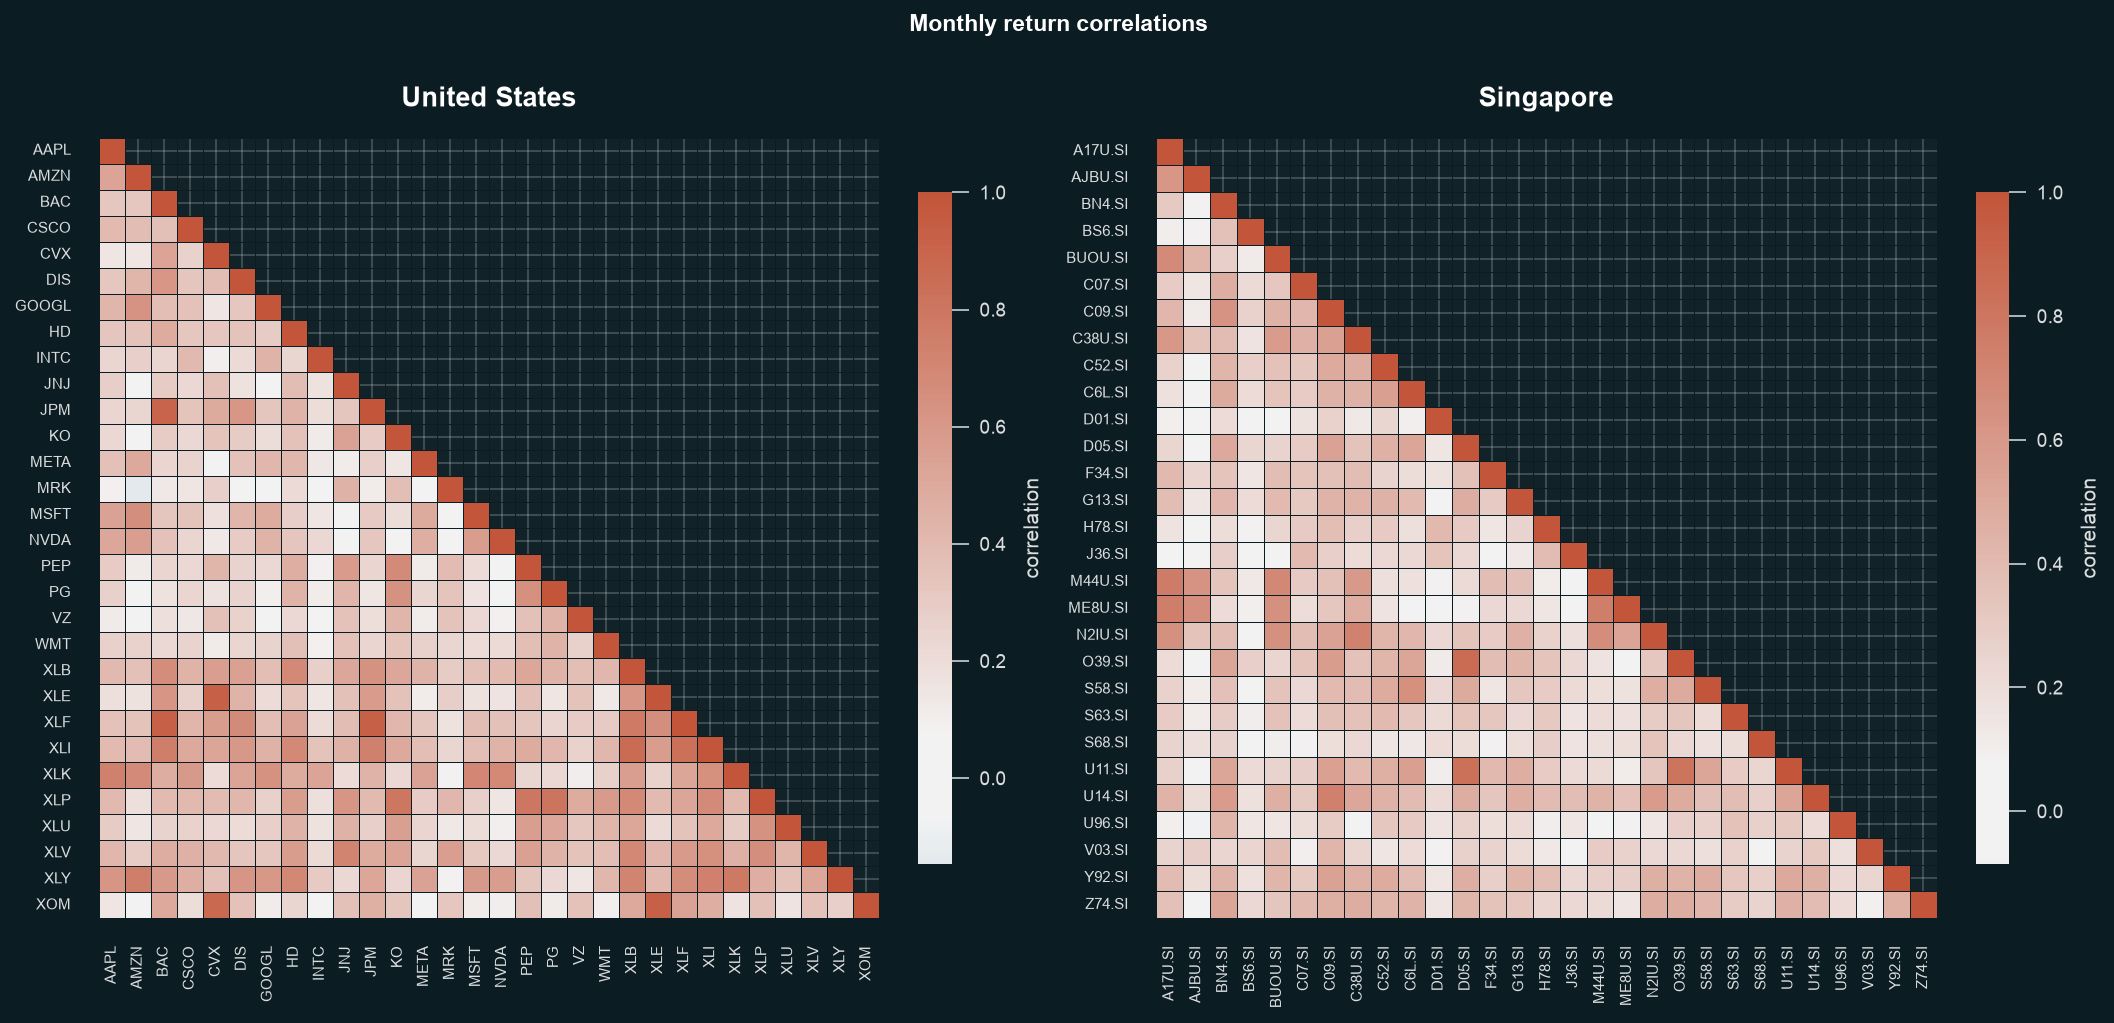

In [3]:
display(Image(filename=viz.plot_correlation_paired(
    {u: RETURNS[u] for u in UNIVERSES}, OUTPUT_DIR / "correlation_paired.png"
)))


## 3. Stage 1: portfolio choice and estimation error

The Mutual Fund Theorem says every efficient portfolio mixes the risk free asset
with the tangency portfolio. We estimate its inputs and compare with the index an
investor could buy.

### (1a) Summary statistics

In [4]:
PORTFOLIO = {
    u: run_portfolio_analysis(
        RETURNS[u],
        rf=risk_free_series(u, RETURNS[u].index),
        comparison=load_value_weights(
            universe=u, assets=RETURNS[u].columns, dates=RETURNS[u].index
        ),
        comparison_label="value weights",
        output_dir=OUTPUT_DIR / u,
    )
    for u in UNIVERSES
}
pd.concat({u.upper(): PORTFOLIO[u].summary for u in UNIVERSES}).round(4)


mean (ann.)  vol (ann.)  sharpe (ann.)  min month  max month
US AAPL           0.292       0.272          0.985     -0.181      0.217
   AMZN           0.233       0.312          0.670     -0.238      0.273
   BAC            0.202       0.286          0.626     -0.250      0.285
   CSCO           0.186       0.249          0.655     -0.155      0.316
   CVX            0.153       0.285          0.453     -0.224      0.273
   DIS            0.068       0.306          0.146     -0.186      0.249
   GOOGL          0.253       0.270          0.852     -0.179      0.338
   HD             0.145       0.229          0.530     -0.151      0.189
   INTC           0.224       0.532          0.377     -0.354      1.141
   JNJ            0.124       0.173          0.585     -0.122      0.144
   JPM            0.226       0.243          0.836     -0.225      0.215
   KO             0.119       0.164          0.586     -0.165      0.129
   META           0.217       0.357          0.542     -0.326      0.272
   MRK            0.145       0.214          0.567     -0.149      0.219
   MSFT           0.259       0.229          1.031     -0.172      0.246
   NVDA           0.607       0.467          1.252     -0.320      0.385
   PEP            0.069       0.161          0.282     -0.096      0.112
   PG             0.090       0.170          0.395     -0.136      0.131
   VZ             0.068       0.190          0.237     -0.117      0.142
   WMT            0.185       0.192          0.840     -0.156      0.129
   XLB            0.117       0.186          0.504     -0.140      0.152
   XLE            0.146       0.302          0.407     -0.344      0.308
   XLF            0.148       0.194          0.644     -0.210      0.168
   XLI            0.146       0.191          0.645     -0.186      0.160
   XLK            0.241       0.210          1.035     -0.120      0.200
   XLP            0.082       0.131          0.450     -0.089      0.105
   XLU            0.098       0.153          0.486     -0.113      0.106
   XLV            0.114       0.146          0.623     -0.094      0.126
   XLY            0.139       0.204          0.567     -0.149      0.189
   XOM            0.146       0.285          0.429     -0.262      0.269
SG A17U.SI        0.064       0.136          0.357     -0.111      0.140
   AJBU.SI        0.125       0.180          0.608     -0.187      0.191
   BN4.SI         0.184       0.231          0.731     -0.166      0.197
   BS6.SI         0.352       0.370          0.912     -0.364      0.299
   BUOU.SI        0.079       0.216          0.297     -0.286      0.245
   C07.SI         0.021       0.236          0.027     -0.267      0.186
   C09.SI         0.049       0.254          0.135     -0.259      0.230
   C38U.SI        0.075       0.169          0.353     -0.211      0.132
   C52.SI        -0.012       0.203         -0.133     -0.221      0.222
   C6L.SI         0.049       0.217          0.158     -0.283      0.280
   D01.SI         0.005       0.250         -0.039     -0.200      0.273
   D05.SI         0.246       0.206          1.120     -0.230      0.248
   F34.SI         0.072       0.185          0.312     -0.186      0.130
   G13.SI         0.050       0.251          0.141     -0.170      0.322
   H78.SI         0.078       0.236          0.267     -0.187      0.212
   J36.SI         0.052       0.228          0.163     -0.129      0.289
   M44U.SI        0.082       0.182          0.368     -0.146      0.152
   ME8U.SI        0.077       0.149          0.417     -0.093      0.136
   N2IU.SI        0.048       0.183          0.178     -0.129      0.186
   O39.SI         0.193       0.172          1.034     -0.185      0.197
   S58.SI         0.035       0.279          0.073     -0.255      0.389
   S63.SI         0.181       0.199          0.833     -0.252      0.255
   S68.SI         0.173       0.168          0.942     -0.167      0.130
   U11.SI         0.144       0.180          0.716     -0.205      0.1


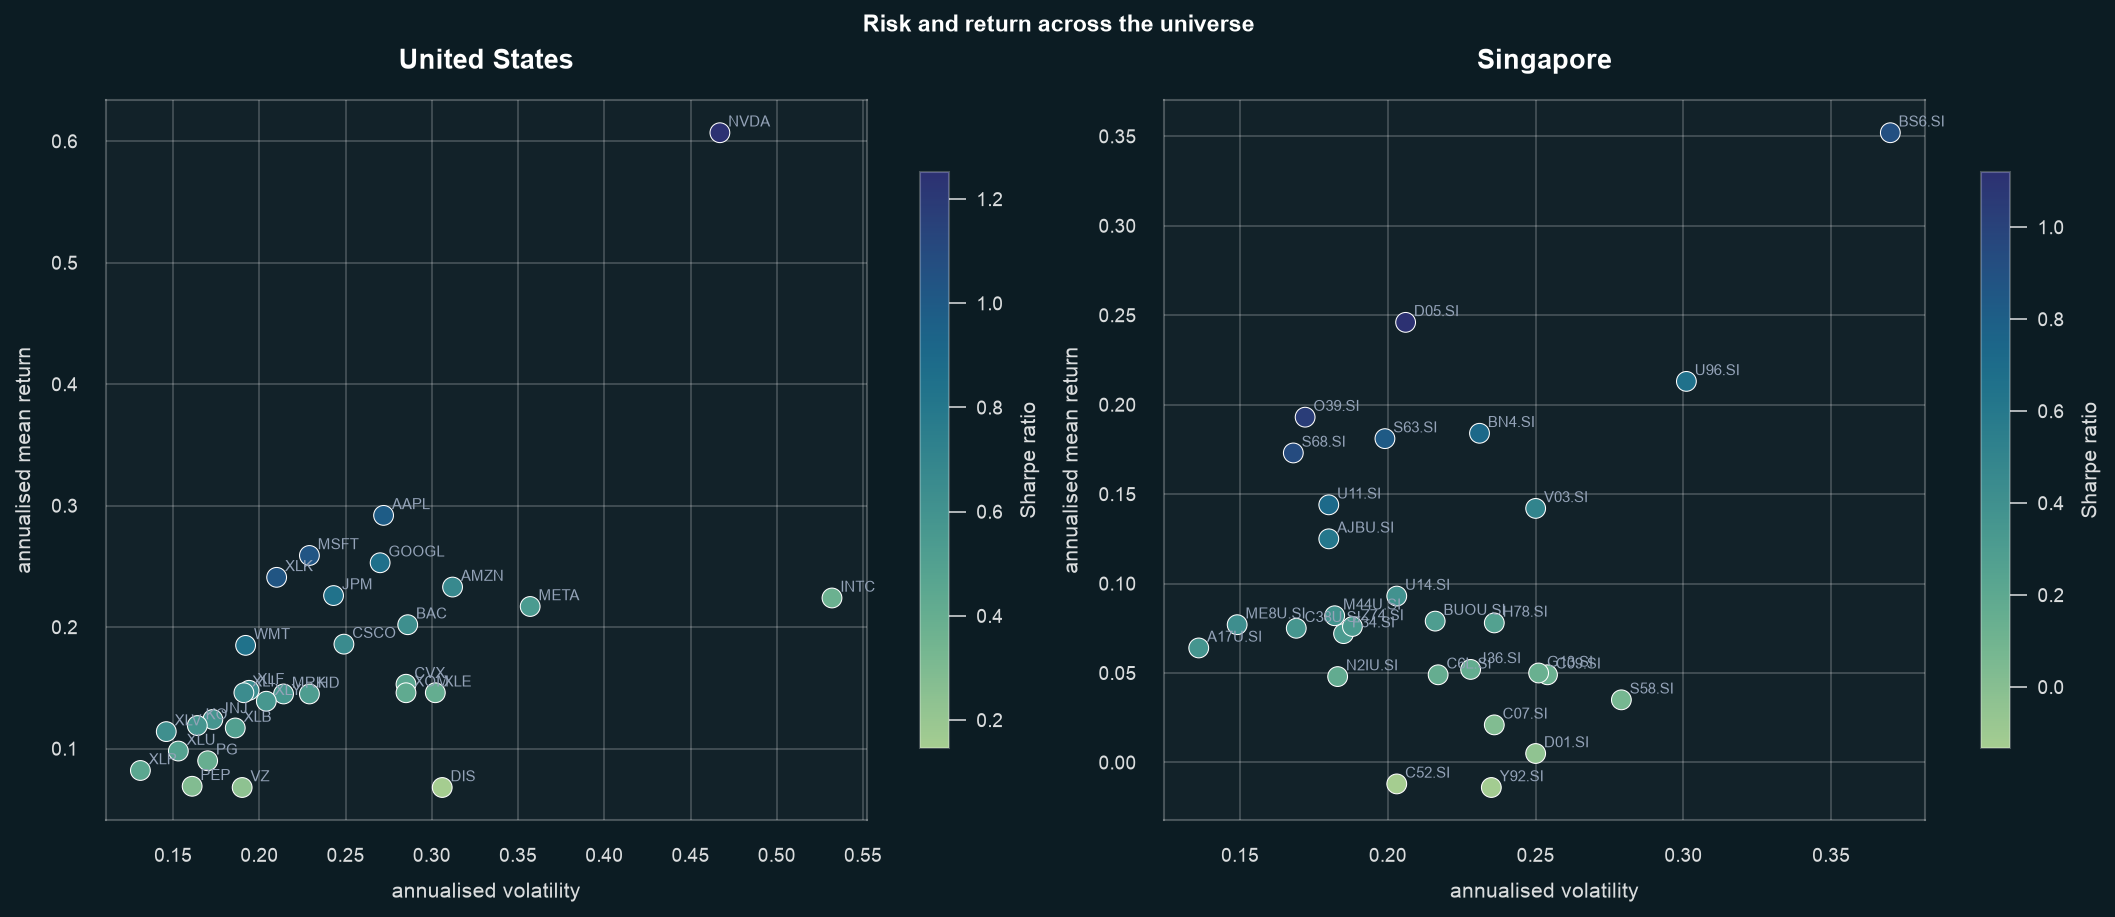

In [5]:
display(Image(filename=viz.plot_risk_return_paired(
    {u: PORTFOLIO[u].summary for u in UNIVERSES}, OUTPUT_DIR / "risk_return_paired.png"
)))


**Takeaway.** Annualised means range from 7% to 61% and volatilities from 13% to
53%, a spread wide enough to make any long-only optimiser look decisive. The means
are the least reliable inputs: they move with the sample window far more than the
volatilities do, so a portfolio built to chase them is largely chasing noise.


### (1b) Tangency weights versus value weights


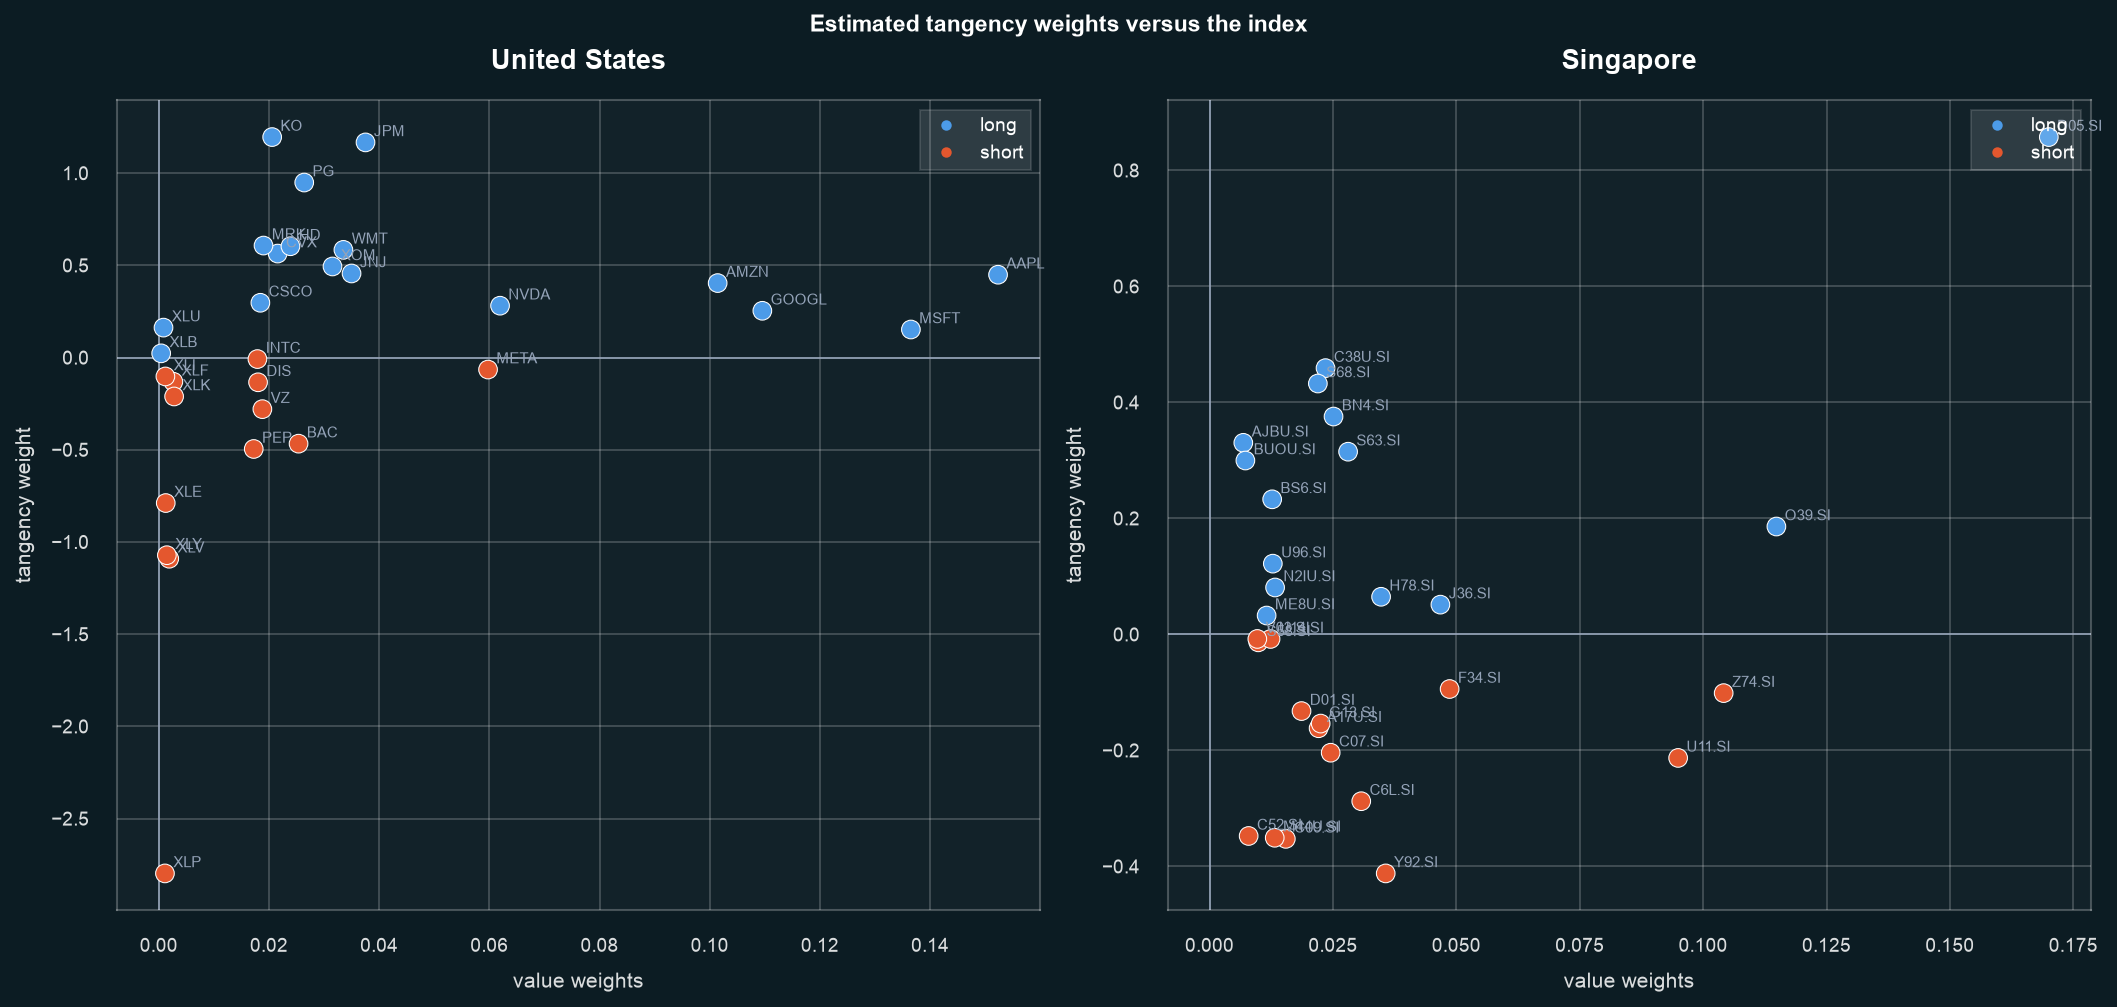

In [6]:
display(Image(filename=viz.plot_weights_paired(
    {u: PORTFOLIO[u].weights for u in UNIVERSES},
    OUTPUT_DIR / "tangency_weights_paired.png",
    comparison_label="value weights",
)))


In [7]:
w = PORTFOLIO[PRIMARY].weights
w.loc[w["tangency"].abs().sort_values(ascending=False).index].head(6).round(3)

,tangency,comparison
XLP,-2.797,0.001
KO,1.196,0.021
JPM,1.167,0.038
XLV,-1.091,0.002
XLY,-1.072,0.001
PG,0.949,0.026


**Takeaway.** Inverting a noisy covariance matrix turns estimation error into
extreme positions: the tangency portfolio shorts one US name by 280% and takes
gross exposure of 16 times the capital it manages. Nothing in the data justifies
those holdings - they are the arithmetic of an inverse applied to inputs we cannot
measure precisely.


### (1c) How stable are the weights?

In [8]:
for u in UNIVERSES:
    print(f"{u.upper()} first and second half weight correlation: "
          f"{PORTFOLIO[u].weight_correlation:.2f}")
pd.concat({u.upper(): PORTFOLIO[u].drift for u in UNIVERSES})


US first and second half weight correlation: 0.35
SG first and second half weight correlation: -0.01


first half  second half  full sample
US AAPL          0.127        1.346        0.449
   AMZN         -0.043        0.111        0.404
   BAC          -0.110       -2.978       -0.467
   CSCO          0.285        0.508        0.297
   CVX           0.572       -0.071        0.564
   DIS           0.223       -0.049       -0.134
   GOOGL         0.172        0.691        0.254
   HD            0.234        1.416        0.604
   INTC          0.049        0.178       -0.008
   JNJ          -0.297        1.470        0.456
   JPM           0.452        3.046        1.167
   KO            0.114        4.716        1.196
   META          0.003       -0.174       -0.065
   MRK           0.251        1.374        0.607
   MSFT          1.048       -0.181        0.152
   NVDA          0.317        0.970        0.281
   PEP           0.245       -2.404       -0.496
   PG            1.062        0.156        0.949
   VZ           -0.555       -0.678       -0.280
   WMT           0.318        0.654        0.584
   XLB          -0.187       -1.151        0.023
   XLE          -0.343        0.356       -0.789
   XLF           0.156        0.986       -0.131
   XLI          -0.434        0.223       -0.102
   XLK          -1.093       -1.182       -0.211
   XLP          -1.676       -4.211       -2.797
   XLU           0.296        0.534        0.162
   XLV           0.293       -4.765       -1.091
   XLY          -0.271       -0.926       -1.072
   XOM          -0.208        1.034        0.494
SG A17U.SI      -0.602        0.092       -0.162
   AJBU.SI       0.979       -0.238        0.330
   BN4.SI        0.028        0.496        0.376
   BS6.SI        0.302        0.153        0.233
   BUOU.SI       0.511        0.134        0.300
   C07.SI       -0.317        0.087       -0.204
   C09.SI       -0.221       -0.238       -0.353
   C38U.SI      -0.123        0.515        0.459
   C52.SI       -0.084       -0.516       -0.348
   C6L.SI       -0.208        0.077       -0.288
   D01.SI        0.208        0.045       -0.132
   D05.SI        0.380        0.710        0.857
   F34.SI       -0.158       -0.400       -0.094
   G13.SI       -0.071        0.230       -0.154
   H78.SI       -0.124        0.197        0.065
   J36.SI        0.260       -0.271        0.051
   M44U.SI      -0.014       -0.636       -0.351
   ME8U.SI      -0.005        0.303        0.033
   N2IU.SI       0.450       -0.298        0.081
   O39.SI       -0.522        0.209        0.186
   S58.SI        0.237        0.065       -0.014
   S63.SI        0.294        0.354        0.315
   S68.SI        0.050        0.366        0.433
   U11.SI        0.520       -0.082       -0.213
   U14.SI        0.106        0.131       -0.008
   U96.SI       -0.143        0.140        0.122
   V03.SI       -0.132       -0.170       -0.008
   Y92.SI       -0.144       -0.451       -0.412
   Z74.SI       -0.459       -0.004       -0.101


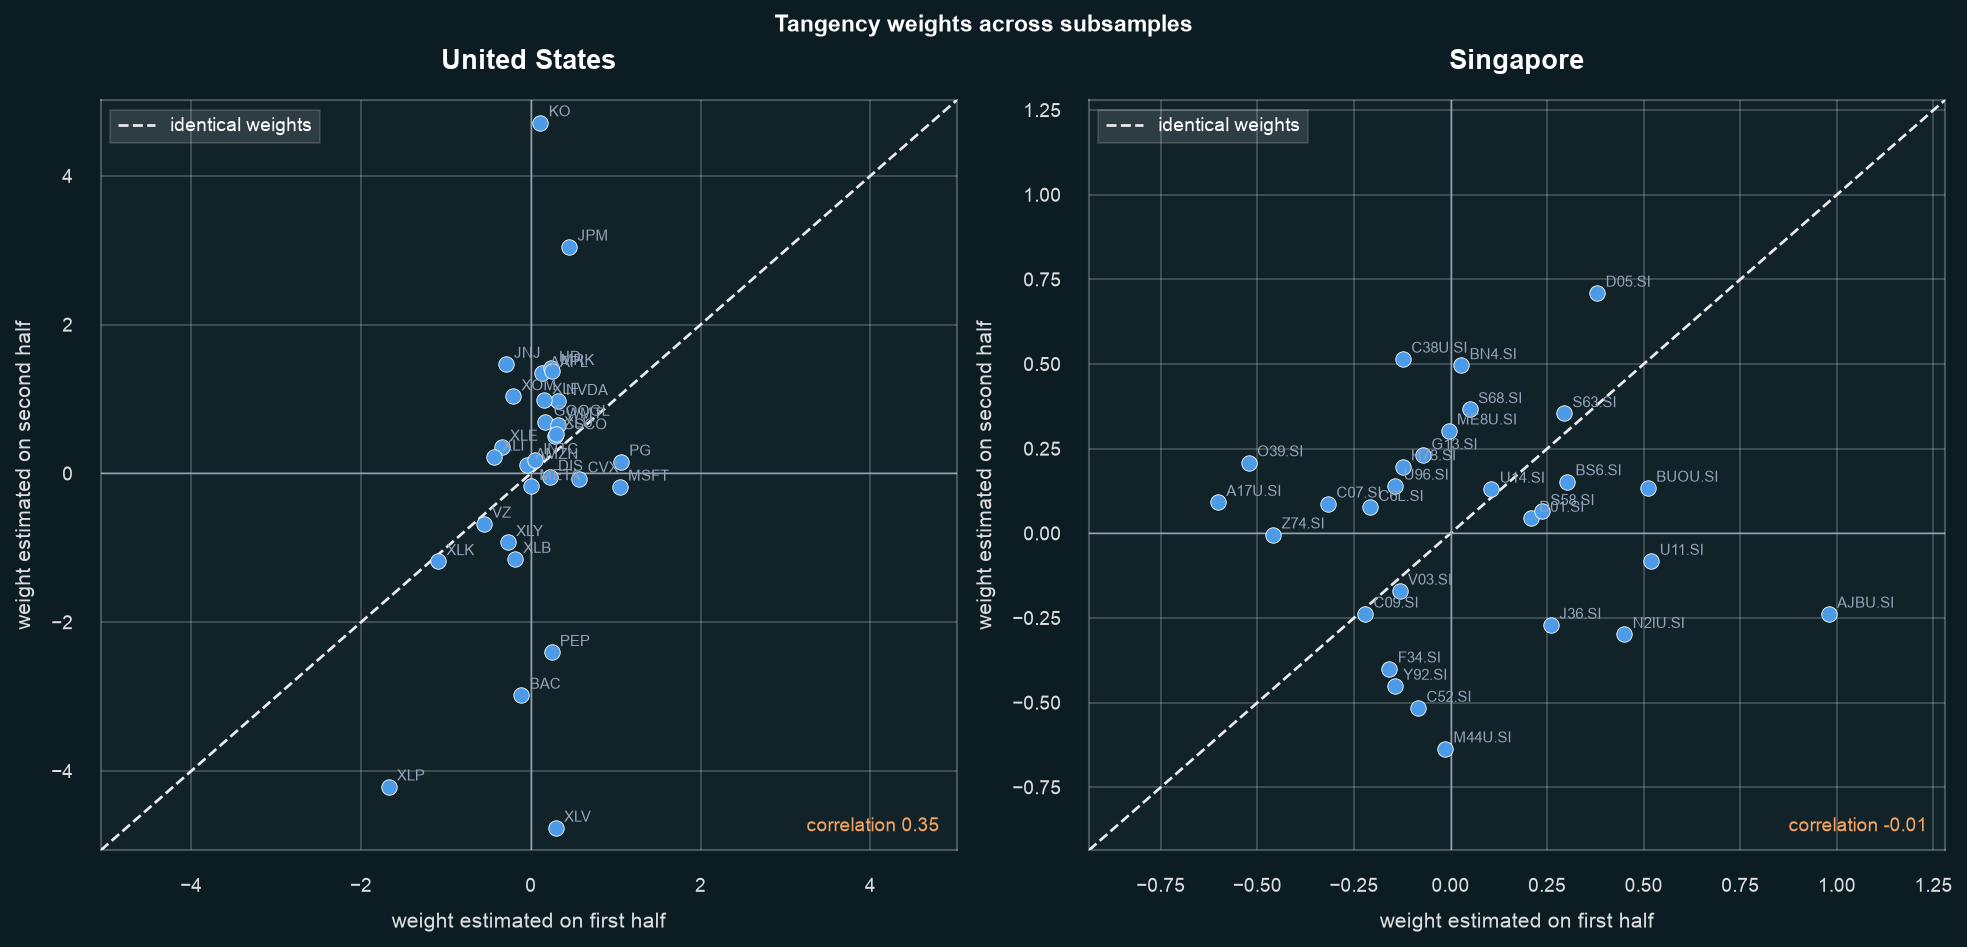

In [9]:
display(Image(filename=viz.plot_weight_drift_paired(
    {u: PORTFOLIO[u].drift for u in UNIVERSES}, OUTPUT_DIR / "weight_drift_paired.png"
)))


**Takeaway.** Re-estimating on each half of the sample produces weights that
correlate at only 0.35. A portfolio whose holdings hardly resemble their own
other-half estimates is not a strategy: the large positions are sampling noise, and
an investor who held the full-sample version would be trading on accidents of the
window.


### Across markets

In [10]:
pd.DataFrame(
    {
        u: {
            "assets": RETURNS[u].shape[1],
            "largest absolute tangency weight": float(PORTFOLIO[u].most_extreme_weight),
            "half sample weight correlation": float(PORTFOLIO[u].weight_correlation),
        }
        for u in UNIVERSES
    }
).T.round(3)

,assets,largest absolute tangency weight,half sample weight correlation
us,30.0,2.797,0.354
sg,29.0,0.857,-0.010


**Takeaway.** Singapore is worse, at -0.01: the weight estimated on the first half
tells you almost nothing about the second. Two different markets agreeing that the
estimates are unstable is stronger evidence than either alone - the problem is the
method, not the sample.


### (1d) Taming the tangency portfolio

Two standard fixes reduce the extremes: a no-short constraint, and shrinkage of
both the covariance and the means.

In [11]:
from goldman.analysis.robustness import LABELS, run_robustness_analysis

FIXES = {
    u: run_robustness_analysis(
        RETURNS[u],
        rf=risk_free_series(u, RETURNS[u].index),
        output_dir=OUTPUT_DIR / u,
        label=u,
    )
    for u in UNIVERSES
}
pd.concat(
    {u: FIXES[u].diagnostics.rename(index=LABELS) for u in UNIVERSES},
    names=["universe", "variant"],
)[["max weight", "min weight", "shorts", "gross leverage", "out of sample Sharpe"]].round(3)


max weight  min weight  shorts  gross leverage  out of sample Sharpe
universe variant                                                                               
us       unconstrained          1.196      -2.797    13.0          16.286                 0.686
         no short               0.201       0.000     0.0           1.000                 0.814
         shrunk                 0.119      -0.055     6.0           1.351                 0.857
         shrunk, no short       0.111       0.000     0.0           1.000                 0.948
sg       unconstrained          0.857      -0.412    15.0           6.680                 0.319
         no short               0.296       0.000     0.0           1.000                 0.721
         shrunk                 0.206      -0.092    10.0           1.728                 0.482
         shrunk, no short       0.200       0.000     0.0           1.000                 0.591


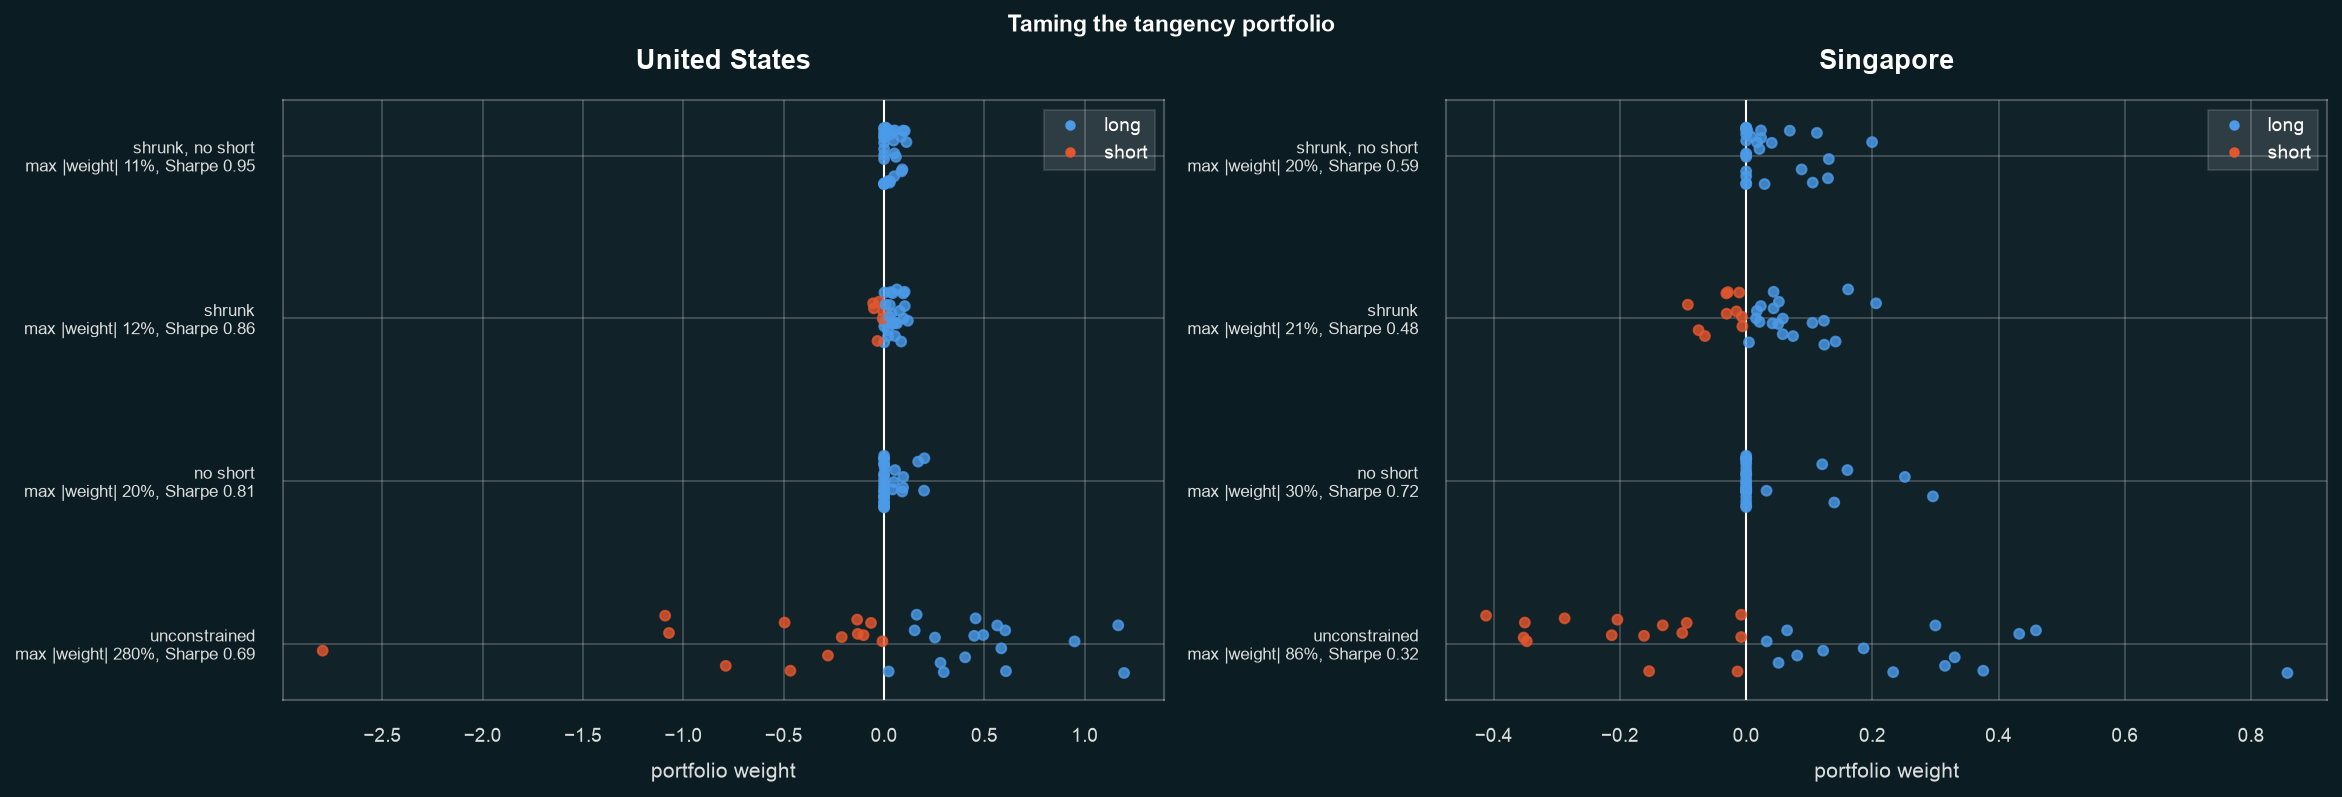

In [12]:
display(Image(filename=viz.plot_robustness_paired(
    {u: FIXES[u].weights for u in UNIVERSES},
    {u: FIXES[u].diagnostics for u in UNIVERSES},
    OUTPUT_DIR / "robustness_paired.png",
)))


**Takeaway.** The fixes are not cosmetic. A no-short constraint and shrinkage of
both the covariance and the means bring the largest position down from 280% to 11%
and gross leverage from 16x to 1.0x, while out-of-sample Sharpe rises from 0.69 for
the raw tangency to 0.95 for the shrunk, long-only version. Restraining the
optimiser costs nothing in return here and removes positions no committee would
approve.


## 4. Stage 2: the CAPM and the empirical SML

Stage 1 asked what an optimizer would hold. Stage 2 asks how returns line up
across assets. The CAPM predicts

$$R_{i,t} - R_{f,t} = \alpha_i + \beta_i\,(R_{M,t} - R_{f,t}) + \varepsilon_{i,t},$$

with nothing left over. We estimate it per asset and test jointly whether the
alphas are zero. With 30 assets, one or two values of |t| above 2 are expected by
chance, so the joint test carries the weight.

### (2a) Security characteristic lines

In [13]:
CAPM = {u: run_capm_analysis(RETURNS[u], universe=u, output_dir=OUTPUT_DIR) for u in UNIVERSES}
pd.concat(
    {
        u.upper(): CAPM[u].table[["beta", "alpha", "t_alpha", "p_alpha", "r_squared", "n"]]
        for u in UNIVERSES
    }
).round(3)


beta  alpha  t_alpha  p_alpha  r_squared    n
   asset                                                  
US AAPL     1.141  0.001    0.112    0.911      0.535  119
   AMZN     1.417 -0.010   -1.777    0.078      0.631  119
   BAC      0.953 -0.003   -0.491    0.624      0.339  119
   CSCO     0.773 -0.001   -0.191    0.849      0.295  119
   CVX      0.575 -0.000   -0.025    0.980      0.124  119
   DIS      1.035 -0.016   -2.288    0.024      0.351  119
   GOOGL    1.119 -0.002   -0.416    0.678      0.527  119
   HD       0.693 -0.003   -0.560    0.577      0.279  119
   INTC     1.243 -0.007   -0.507    0.613      0.167  119
   JNJ      0.280  0.003    0.652    0.516      0.080  119
   JPM      0.740  0.003    0.482    0.630      0.285  119
   KO       0.295  0.002    0.533    0.595      0.099  119
   META     1.238 -0.007   -0.932    0.354      0.370  119
   MRK      0.117  0.008    1.301    0.196      0.009  119
   MSFT     1.031 -0.000   -0.005    0.996      0.621  119
   NVDA     1.847  0.013    1.408    0.162      0.480  119
   PEP      0.352 -0.003   -0.685    0.495      0.144  119
   PG       0.291  0.000    0.011    0.991      0.089  119
   VZ       0.254 -0.001   -0.208    0.836      0.055  119
   WMT      0.456  0.005    0.964    0.337      0.173  119
   XLB      0.680 -0.005   -1.265    0.208      0.407  119
   XLE      0.671 -0.003   -0.324    0.747      0.151  119
   XLF      0.696 -0.003   -0.667    0.506      0.393  119
   XLI      0.749 -0.004   -1.023    0.308      0.472  119
   XLK      1.091 -0.003   -1.065    0.289      0.824  119
   XLP      0.390 -0.003   -0.786    0.433      0.269  119
   XLU      0.338 -0.000   -0.055    0.956      0.148  119
   XLV      0.449 -0.001   -0.278    0.781      0.287  119
   XLY      0.990 -0.009   -3.021    0.003      0.721  119
   XOM      0.475  0.001    0.146    0.884      0.085  119
SG A17U.SI  0.494 -0.001   -0.371    0.711      0.220  119
   AJBU.SI  0.251  0.006    1.318    0.190      0.032  119
   BN4.SI   1.235  0.001    0.195    0.846      0.477  119
   BS6.SI   0.946  0.018    1.865    0.065      0.109  119
   BUOU.SI  0.796 -0.003   -0.599    0.550      0.226  119
   C07.SI   0.939 -0.009   -1.697    0.092      0.264  119
   C09.SI   1.440 -0.013   -2.612    0.010      0.535  119
   C38U.SI  0.787 -0.003   -0.918    0.361      0.362  119
   C52.SI   0.936 -0.012   -2.730    0.007      0.357  119
   C6L.SI   1.068 -0.009   -1.850    0.067      0.406  119
   D01.SI   0.530 -0.006   -0.972    0.333      0.075  119
   D05.SI   1.365  0.005    1.577    0.118      0.731  119
   F34.SI   0.759 -0.003   -0.761    0.448      0.281  119
   G13.SI   1.113 -0.009   -1.564    0.120      0.327  119
   H78.SI   0.858 -0.004   -0.676    0.500      0.220  119
   J36.SI   0.677 -0.004   -0.709    0.480      0.147  119
   M44U.SI  0.554 -0.000   -0.069    0.945      0.153  119
   ME8U.SI  0.320  0.002    0.446    0.657      0.077  119
   N2IU.SI  0.816 -0.006   -1.440    0.152      0.330  119
   O39.SI   1.143  0.003    1.074    0.285      0.736  119
   S58.SI   1.281 -0.012   -1.927    0.056      0.351  119
   S63.SI   0.734  0.006    1.239    0.218      0.227  119
   S68.SI   0.460  0.008    1.907    0.059      0.125  119
   U11.SI   1.168 -0.002   -0.625    0.533      0.700  119
   U14.SI   1.049 -0.005   -1.118    0.266      0.444  119
   U96.SI   0.852  0.007    0.961    0.339      0.134  119
   V03.SI   0.661  0.004    0.542    0.589      0.116  119
   Y92.SI   1.208 -0.015   -3.149    0.002      0.441  119
   Z74.SI   0.978 -0.005   -1.408    0.162      0.455  119


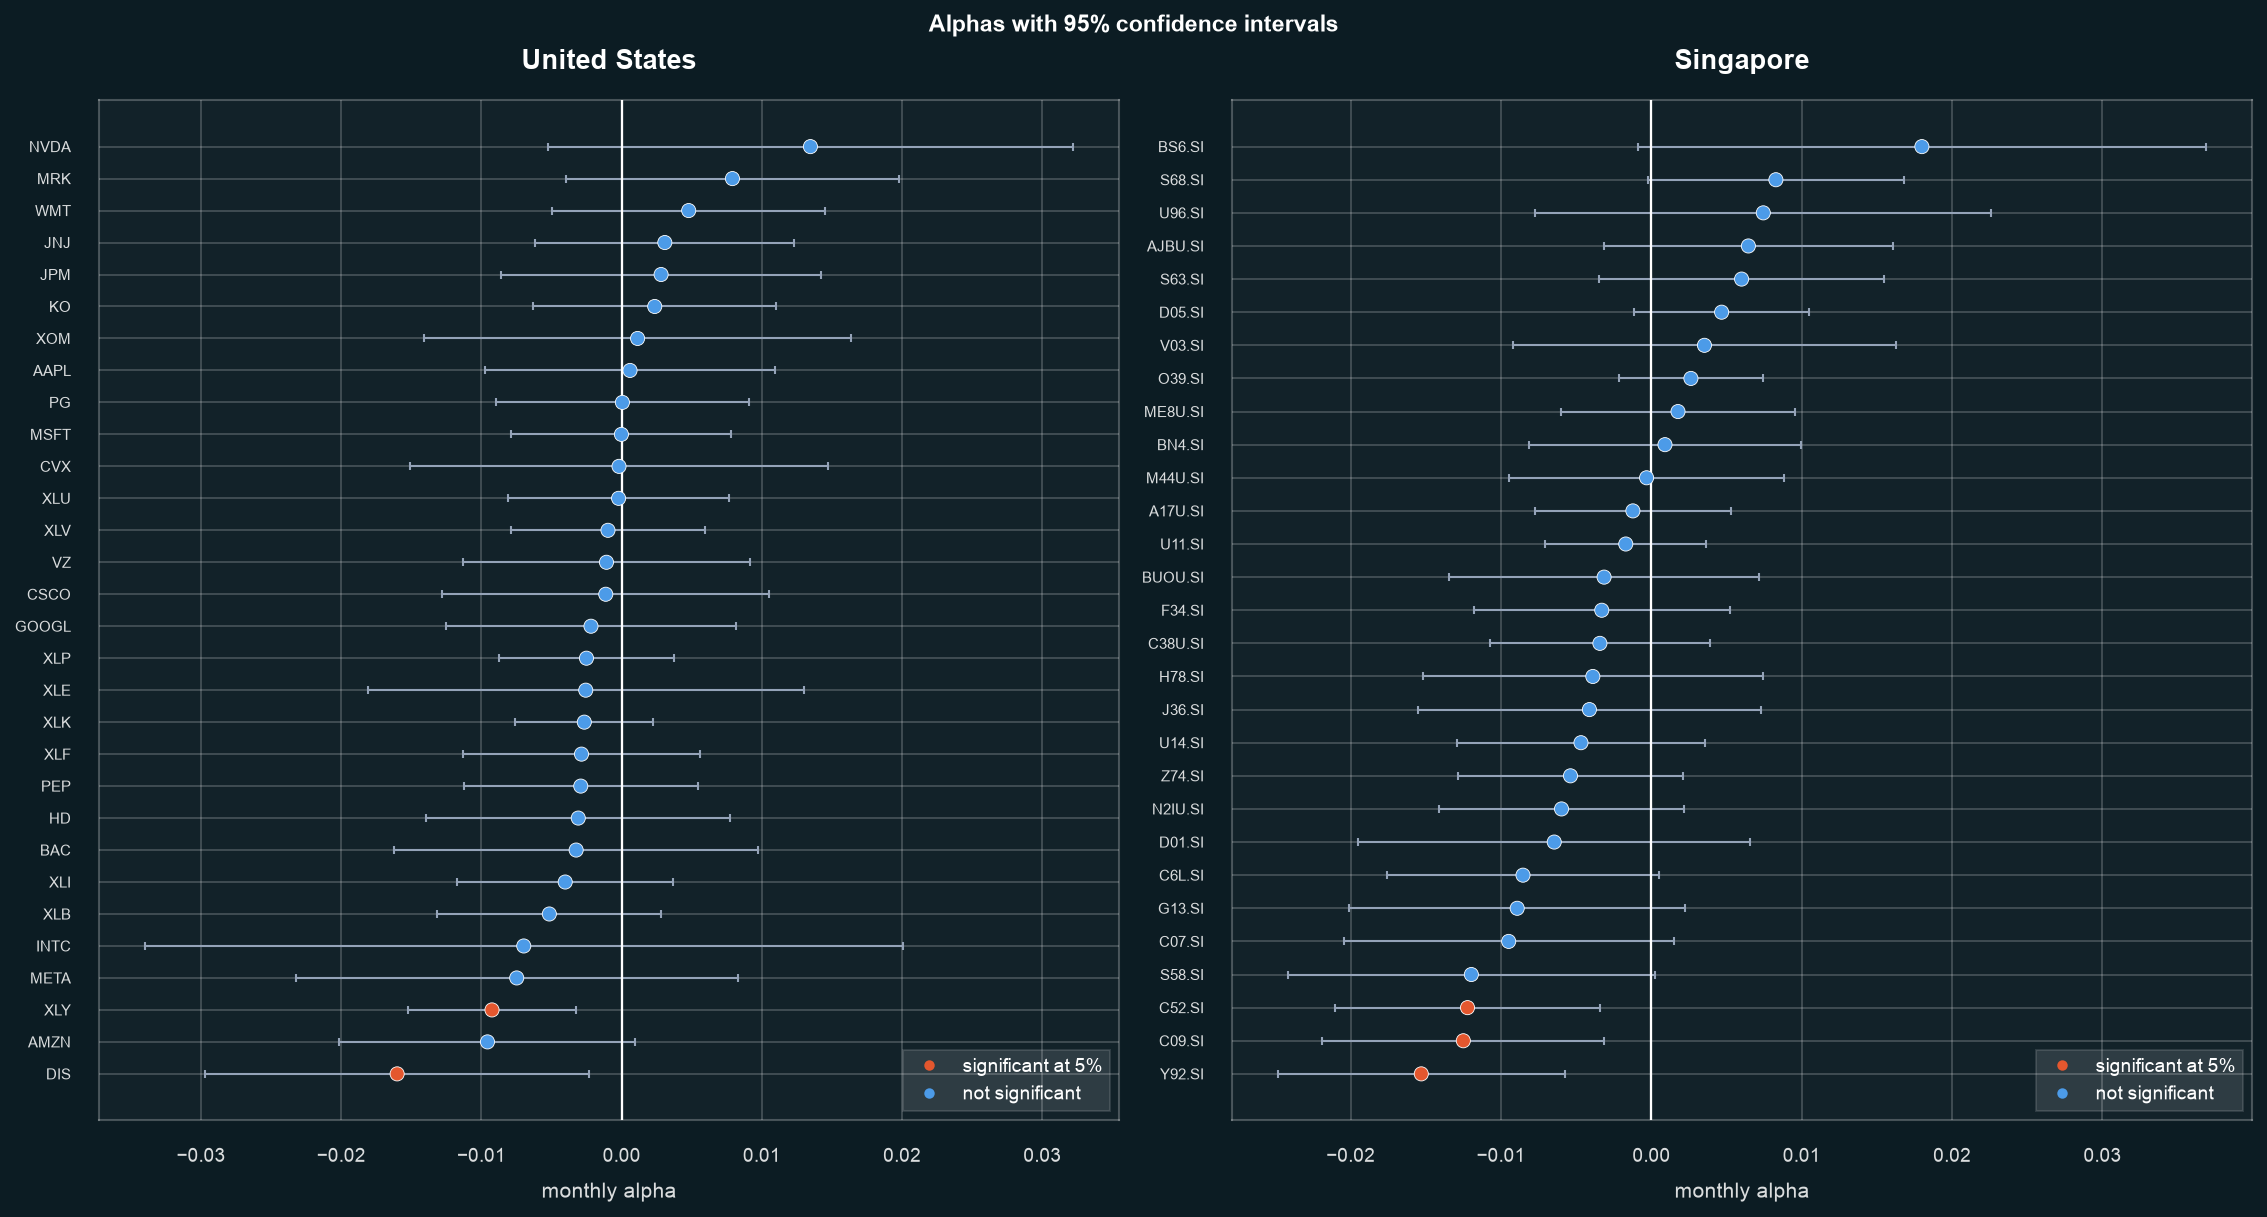

In [14]:
display(Image(filename=viz.plot_alpha_intervals_paired(
    {u: CAPM[u].table for u in UNIVERSES}, OUTPUT_DIR / "alpha_intervals_paired.png"
)))


**Takeaway.** Betas are estimated precisely - the market factor explains a large
share of each name's variance and the standard errors are small - while alphas are
noisy: only 2 of 30 assets reach |t| > 2, and about 1.5 are expected by chance
alone. The market prices systematic risk tightly; it says much less about the
leftover average return.


### (2b) The empirical SML


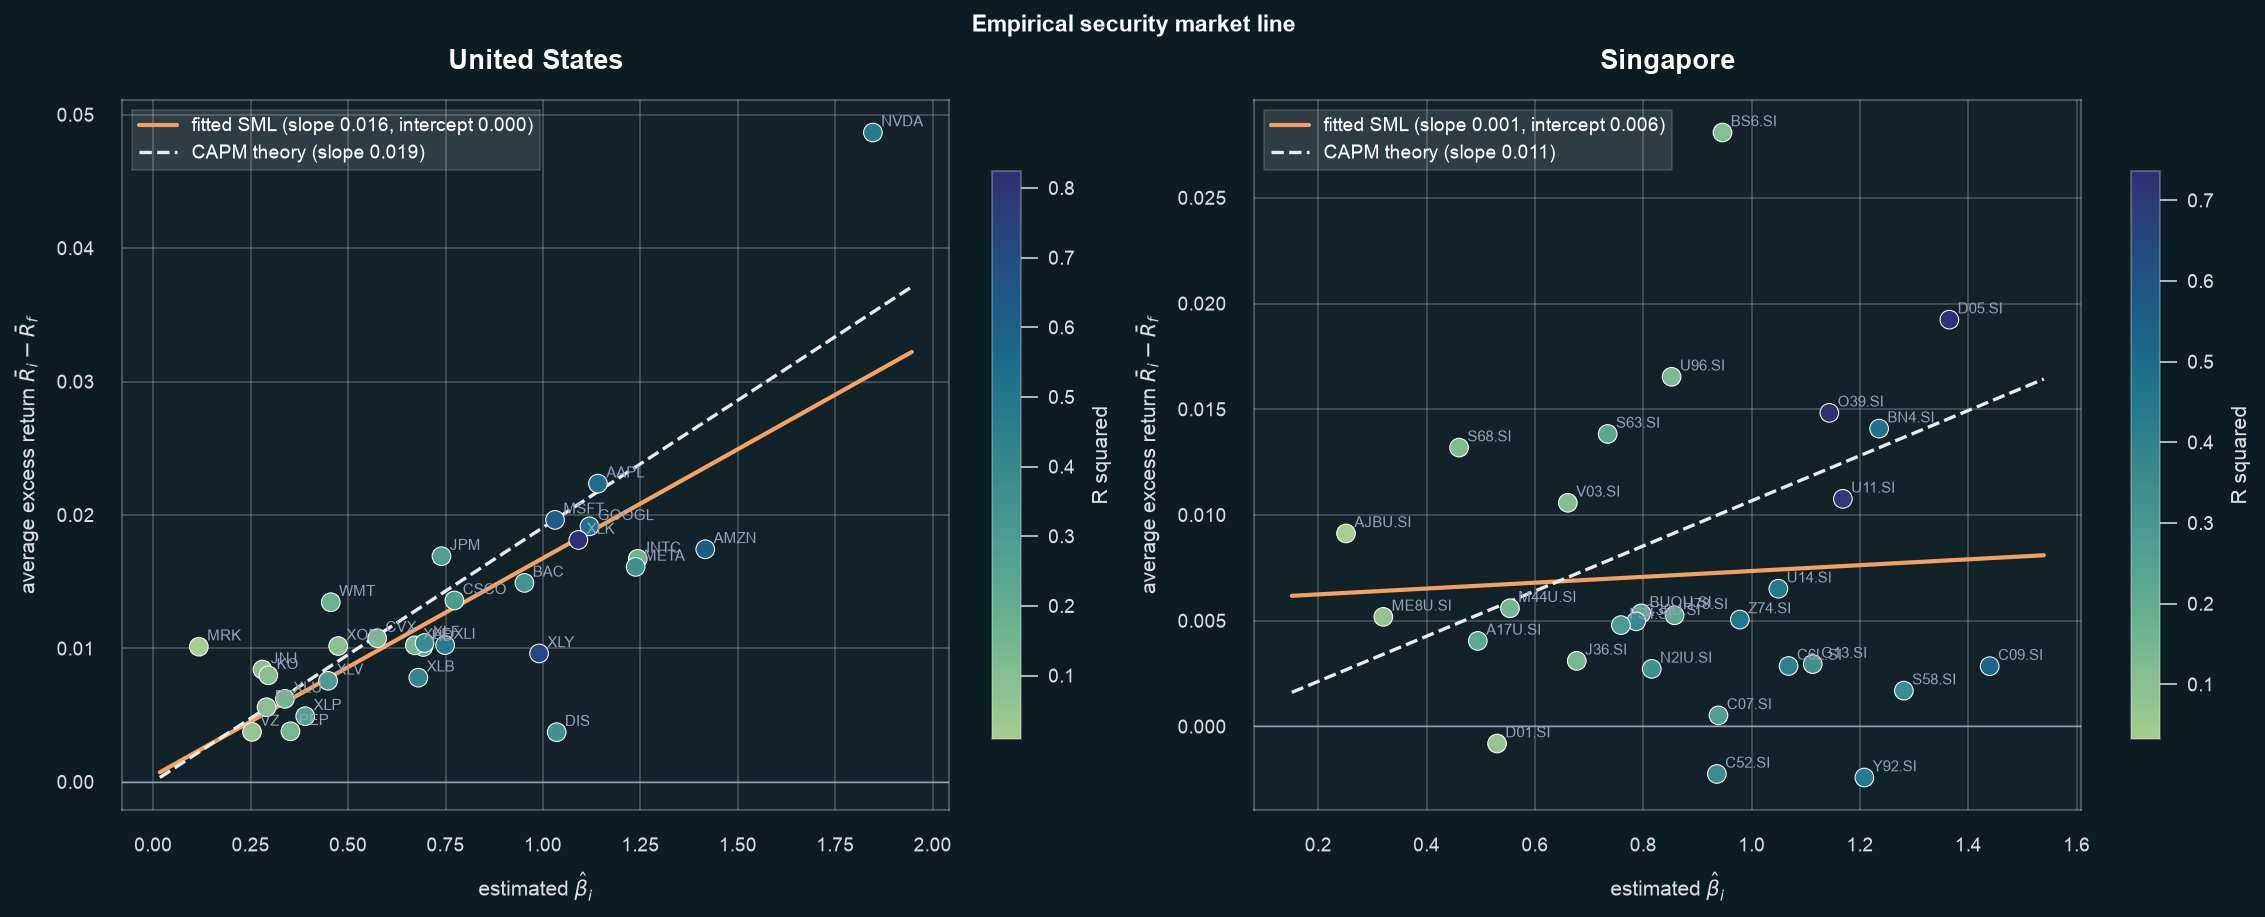

In [15]:
display(Image(filename=viz.plot_sml_paired(
    {u: CAPM[u].table for u in UNIVERSES},
    {u: CAPM[u].fit for u in UNIVERSES},
    OUTPUT_DIR / "sml_paired.png",
)))


**Takeaway.** The empirical SML is flatter than theory in both markets, and in
Singapore it is almost flat, so neither matches the line through the origin. The
US scatter also hugs its fitted line far more closely than Singapore's, where beta
explains almost none of the spread in average returns: the market factor
organises US risk well and Singapore risk poorly.


### (2c) Are all alphas zero?

**The GRS p value** is the probability of seeing alphas this large if every true
alpha were zero, so a value below 0.05 rejects the CAPM.

In [16]:
pd.DataFrame(
    {
        u: {
            "assets": int(c.fit.n),
            "alphas p<0.05": int((c.table["p_alpha"] < 0.05).sum()),
            "expected by chance": round(0.05 * len(c.table), 1),
            "GRS F": c.grs["f_stat"],
            "GRS p": c.grs["p_value"],
        }
        for u, c in CAPM.items()
    }
).T.round(3)

,assets,alphas p<0.05,expected by chance,GRS F,GRS p
us,30.0,2.0,1.5,1.008,0.469
sg,29.0,3.0,1.5,1.472,0.086



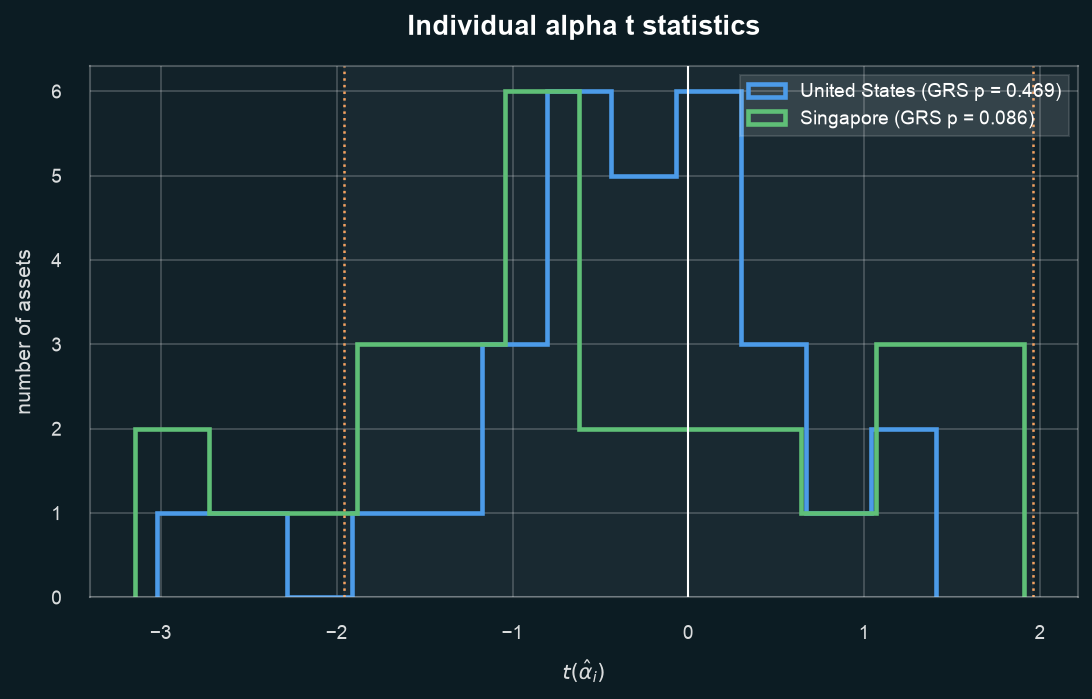

In [17]:
display(Image(filename=viz.plot_grs(CAPM, OUTPUT_DIR / "grs.png")))

**Takeaway.** The US cannot reject zero alphas (GRS p = 0.47) with 2 of 30
individually significant; Singapore is marginal (p = 0.09) with 3 of 29. Read
together, the US is consistent with the CAPM and Singapore is a warning that the
joint test, not the count of stars, is the one that matters.


### (2d) Fitted versus theoretical SML

In [18]:
pd.DataFrame(
    {
        u: {
            "fitted slope": c.fit.slope,
            "theoretical slope": c.fit.theoretical_slope,
            "fitted intercept": c.fit.intercept,
            "cross sectional R2": c.fit.r_squared,
        }
        for u, c in CAPM.items()
    }
).T.round(4)

,fitted slope,theoretical slope,fitted intercept,cross sectional R2
us,0.0163,0.0191,0.0004,0.6100
sg,0.0014,0.0107,0.0060,0.0038



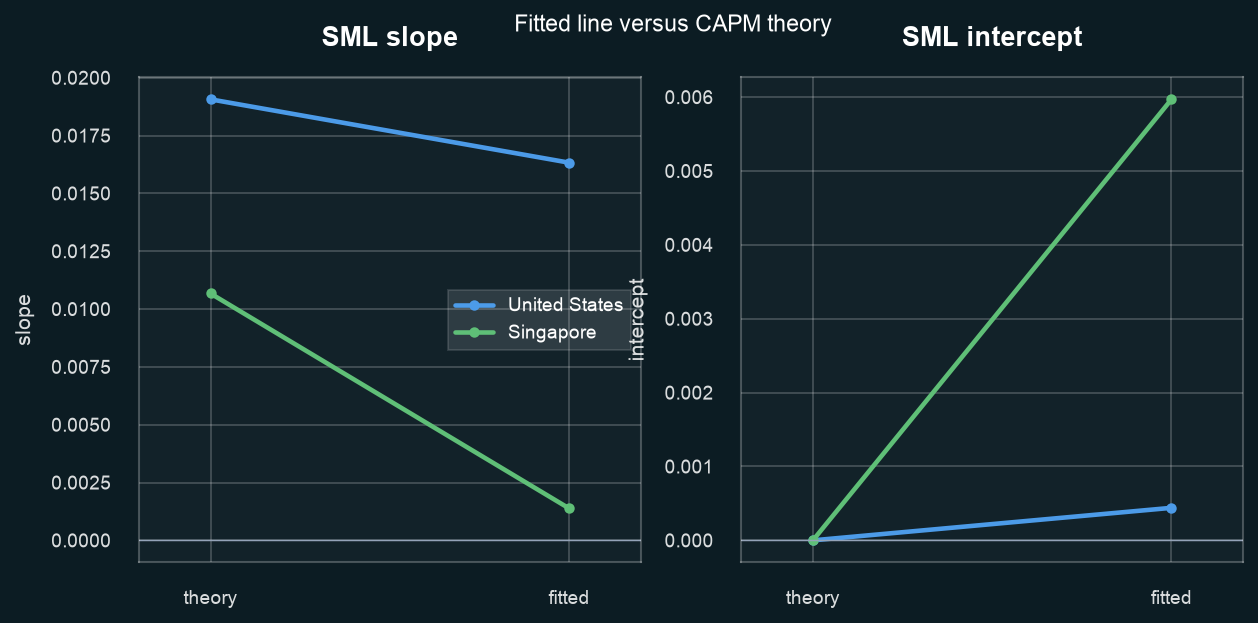

In [19]:
display(Image(filename=viz.plot_sml_fit(CAPM, OUTPUT_DIR / "sml_fit.png")))

**Takeaway.** The US slope is too flat (0.016 against a theoretical 0.019) and its
intercept is essentially zero, while Singapore's slope is close to zero (0.001
against 0.011) with a positive intercept of 0.006 a month. Theory wants a zero
intercept and a slope equal to the average market excess return; the US misses on
the slope, Singapore on both in the classic direction - too flat, intercept too
high - and their cross-sectional fits differ (R squared 0.61 versus 0.004).


## 5. Stage 3: factors

Stage 2 left the market as the only source of common variation. Stage 3 adds four
factors: size, momentum, low volatility and short-term reversal. For the US we use
Ken French's factors as the external benchmark; because Singapore has no free
factor library, we build all four factors ourselves and run them on both markets.
Every model is estimated on one common sample (the months where all factors
exist) and, within a market, against the same market factor, so an alpha that
shrinks cannot be an artefact of a shorter window or a different proxy.


### (3a) How the factors are built

**Size (SMB).** Each month we rank the assets by market capitalisation at the
*previous* month end, using the committed point-in-time value weights so the sort
never sees the month it is predicting. We go long the small-cap third and short
the large-cap third, equal-weighted, and take the difference — the Fama and
French 30/40/30 convention, which drops the middle third.

**Momentum (WML).** We rank by the compounded return from month t-12 to t-2, the
standard 12-1 formation that skips the most recent month to avoid short-term
reversal, and go long the winners and short the losers.

**Low volatility (LOWVOL).** We rank by the standard deviation of an asset's
returns over months t-12 to t-1, again using only realised history, and go long
the calmest third and short the most volatile third. The bet is that low-risk
names earn more than their market betas imply.

**Short-term reversal (REV).** We rank on last month's return and go long the
previous month's losers and short its winners — the one-month reversal that the
12-1 momentum rule deliberately skips.

All four factors are built from the same returns they help explain; that is
deliberate, and it is why a factor can mechanically absorb cross-sectional
variation.



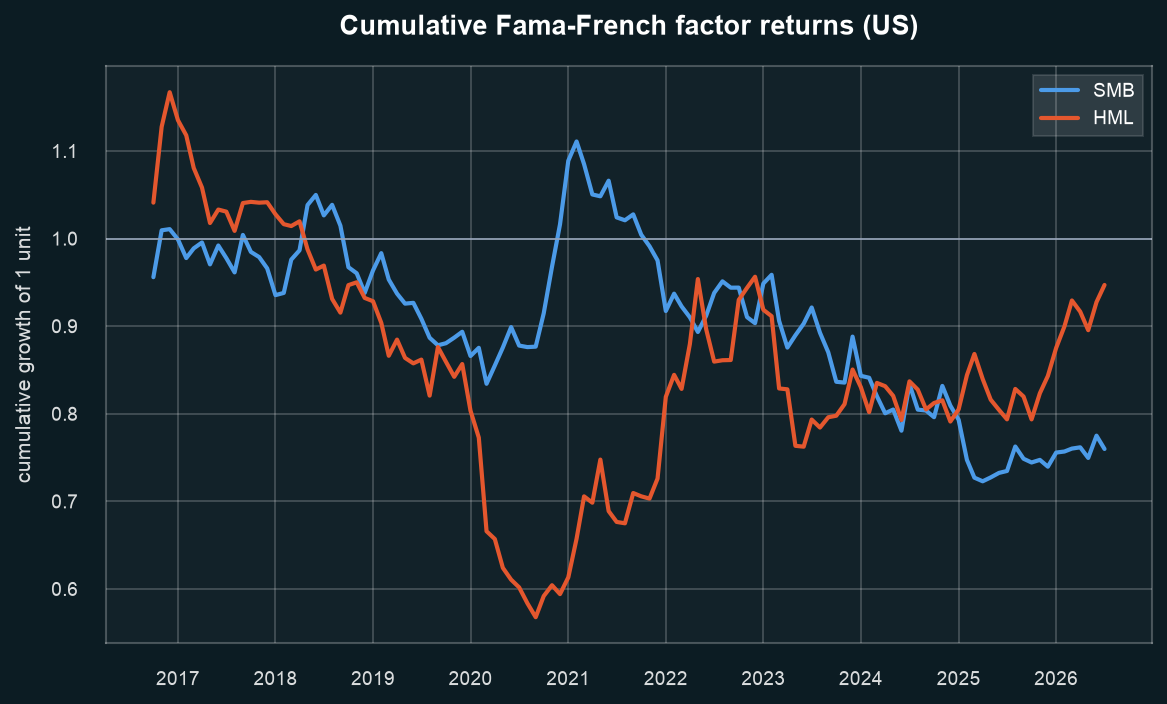

mean (ann.)  vol (ann.)  months
us SMB          -0.030       0.101   118.0
   WML           0.037       0.165   107.0
   LOWVOL       -0.141       0.164   107.0
   REV          -0.057       0.142   118.0
sg SMB           0.047       0.101   118.0
   WML           0.088       0.144   107.0
   LOWVOL        0.021       0.112   107.0
   REV          -0.007       0.103   118.0

In [20]:
from goldman.analysis import build_self_factors

BUILT = {u: build_self_factors(RETURNS[u], universe=u) for u in UNIVERSES}
SELF_FACTORS = list(BUILT[PRIMARY].columns)

# The US has a downloadable factor library, so its own panel shows the real
# Fama-French SMB and HML; the self-built spreads for both markets are paired
# on the next exhibit.
FF3 = load_ff3()
FF3.index = FF3.index.to_timestamp()
FF_FACTORS = FF3[["SMB", "HML"]].reindex(RETURNS["us"].index)

display(Image(filename=viz.plot_factor_cumulative(
    FF_FACTORS,
    OUTPUT_DIR / "factor_cumulative_us.png",
    title="Cumulative Fama-French factor returns (US)",
)))
pd.concat(
    {
        u: pd.DataFrame(
            {
                factor: {
                    "mean (ann.)": BUILT[u][factor].mean() * 12,
                    "vol (ann.)": BUILT[u][factor].std() * np.sqrt(12),
                    "months": int(BUILT[u][factor].notna().sum()),
                }
                for factor in SELF_FACTORS
            }
        ).T
        for u in UNIVERSES
    }
).round(3)



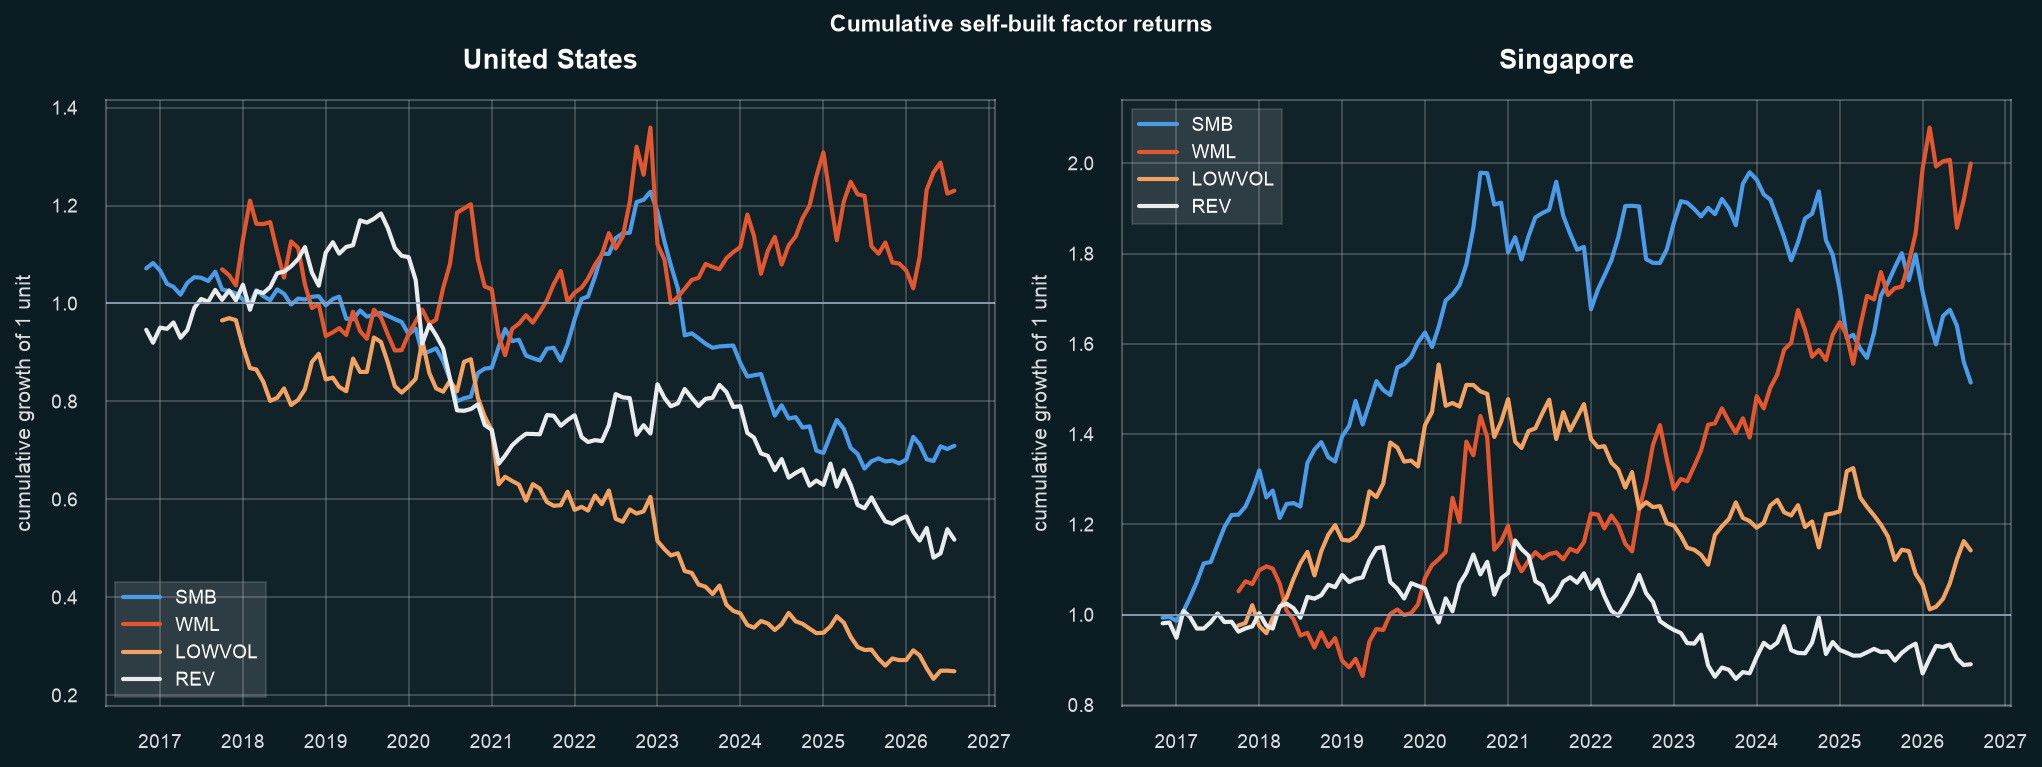

In [21]:
display(Image(filename=viz.plot_factor_cumulative_paired(
    {u: BUILT[u] for u in UNIVERSES}, OUTPUT_DIR / "factor_cumulative_paired.png"
)))


**Takeaway.** The panels answer the same question from different
directions. For the US we can download the factors, and over this sample they are
subdued: SMB drifts steadily lower and HML is roughly flat, after a deep value
drawdown through 2020. That calm is why Stage 3's US factor alphas barely move.
Singapore has no free library, so its panel is our own construction. Its momentum
spread doubles its starting value (8.8% a year) and the size spread gains about
half (4.7%), while low volatility adds a modest 2.1% and reversal is flat
(-0.7%). The US self-built versions are poorer: size loses 3.0% a year, reversal
5.7%, and low volatility 14.1%, as the volatile mega-caps that led the decade kept
winning. The spreads are noisy, with annual volatility from 10% (size) to 16%
(momentum and low volatility), and because the universe is built from mega-caps
the "small" leg is barely small, so the self-built size factor is a weak proxy at
best. The table above reports that self-built construction for both markets,
which is the object the factor models actually use.


### (3b) The cost of trading the factors

A spread earns marks on paper, not in a portfolio. All four factors rebalance
every month, so the returns above are gross of the trading they require. We
rebuild the same weights - SMB from the lagged value weights, WML from the 12-1
signal, LOWVOL from trailing volatility and REV from last month's return, each on
the 30/40/30 split of (3a) - measure one-way turnover as the sum of absolute
weight changes, and charge a per-unit cost on it. Because the charge is linear,
the net mean is a straight line in the cost and crosses zero at the break-even
cost.

**Exhibit 6. The cost of trading the four self-built factors.** Each market gets
its own column: the top row is the annualised mean of each factor net of a
per-unit-turnover cost, with its break-even cost marked, and the bottom row is
peak-to-trough drawdown. The factors share a panel so they can be read against
each other.



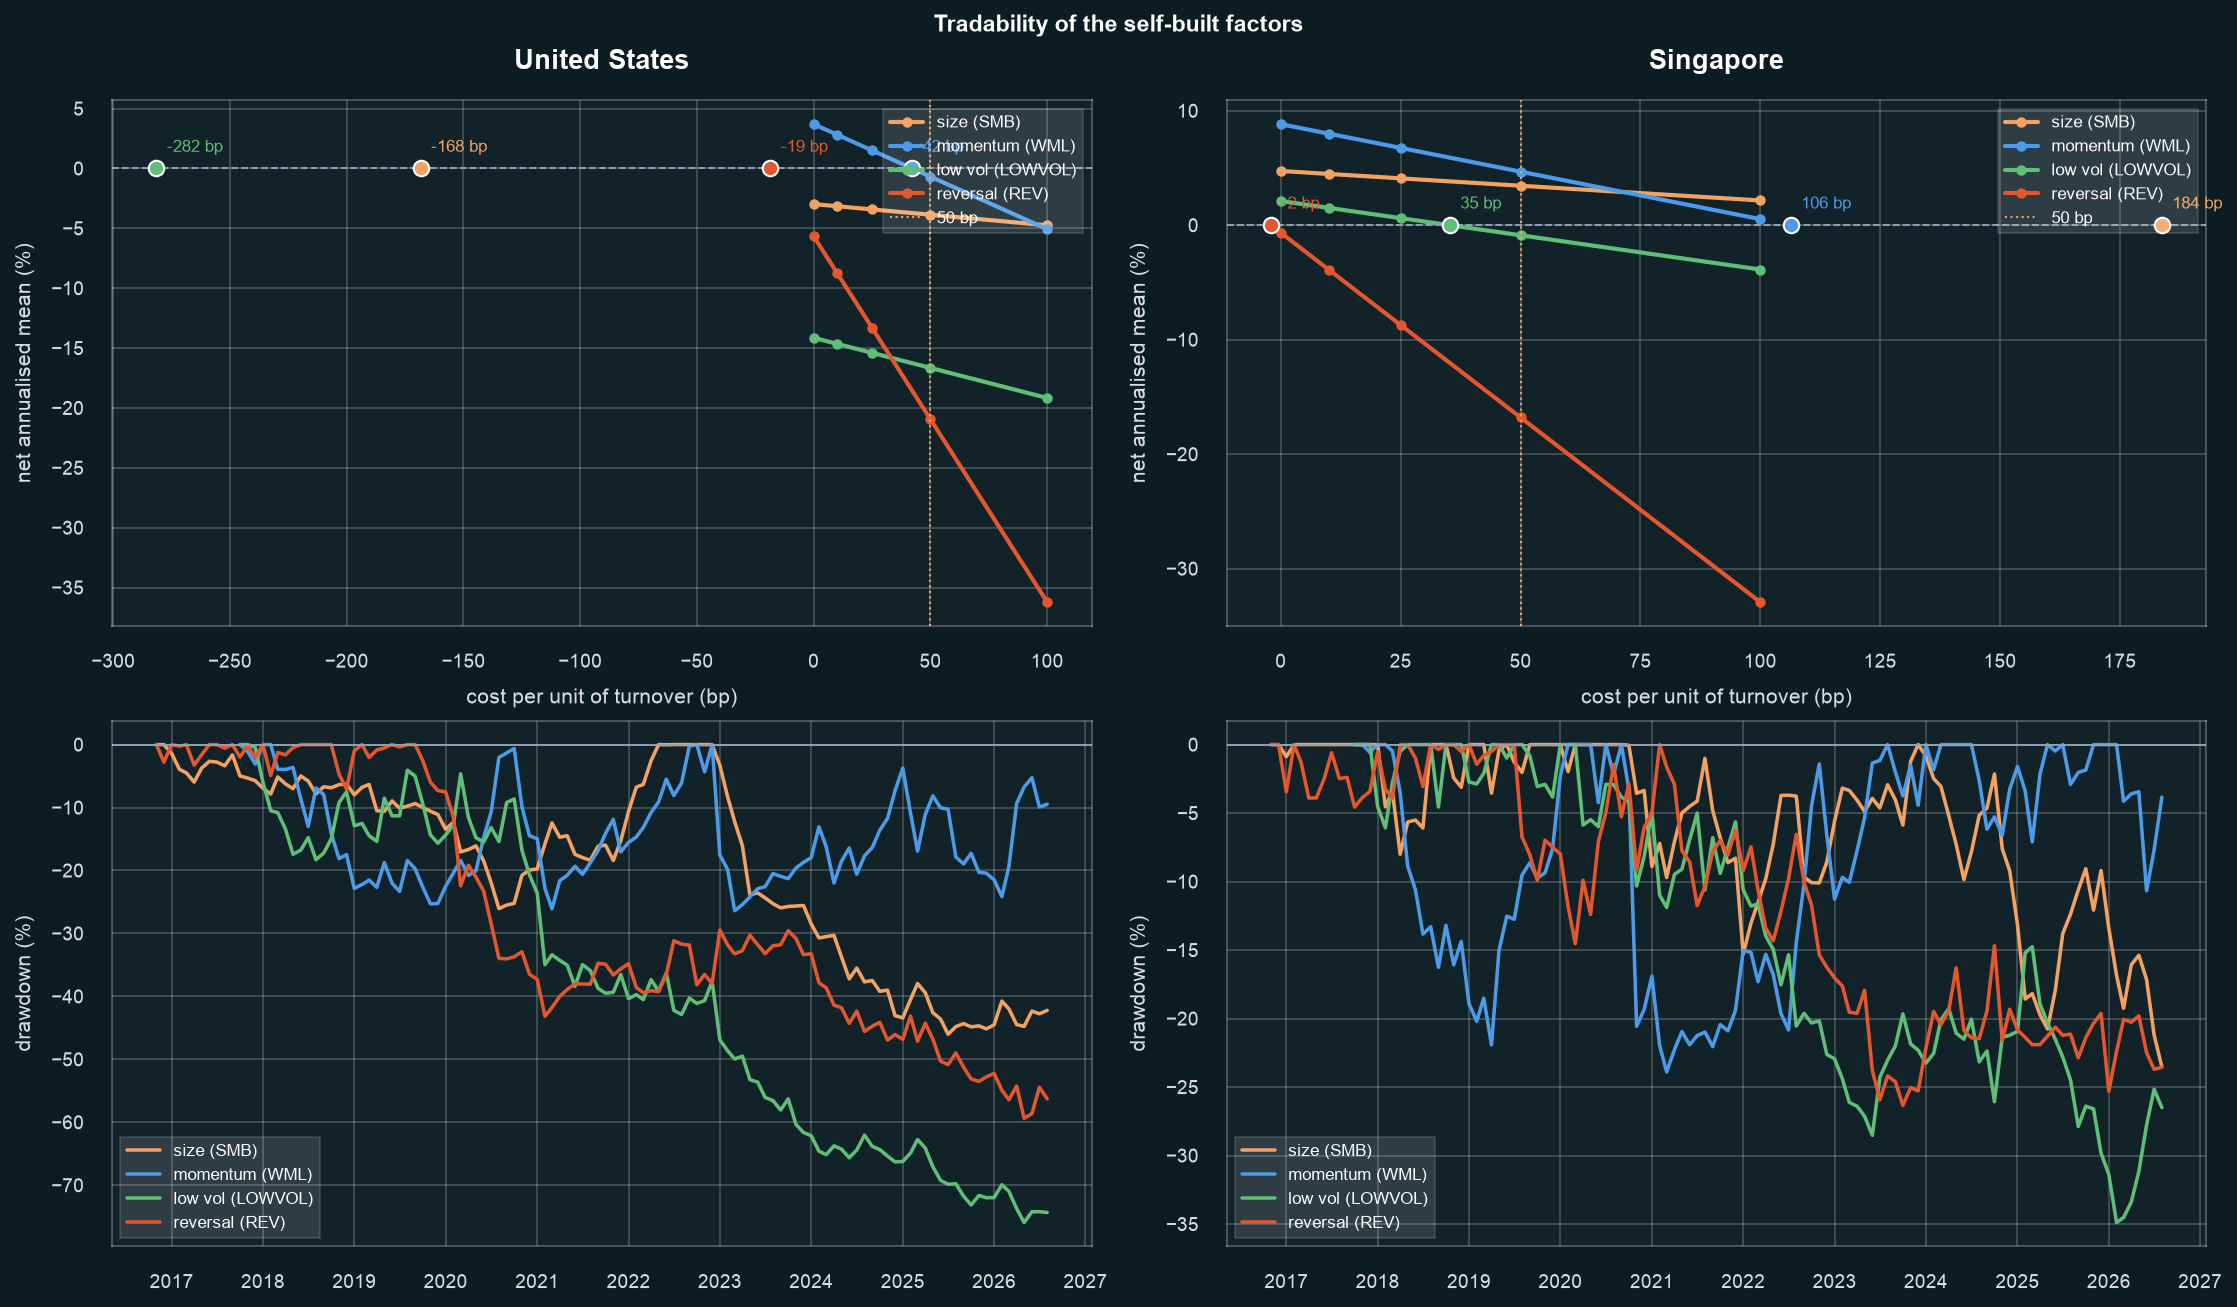

months  gross mean (ann.)  turnover / month  break-even cost (bp)  net at 50bp (ann.)  max drawdown
market factor                                                                                                     
us     SMB      118.0             -0.030             0.147              -168.333              -0.039        -0.460
       WML      107.0              0.037             0.731                42.184              -0.007        -0.264
       LOWVOL   107.0             -0.141             0.419              -281.538              -0.167        -0.759
       REV      118.0             -0.057             2.546               -18.565              -0.209        -0.594
sg     SMB      118.0              0.047             0.215               183.758               0.034        -0.235
       WML      107.0              0.088             0.692               106.340               0.047        -0.239
       LOWVOL   107.0              0.021             0.498                35.261              -0.009        -0.349
       REV      118.0             -0.007             2.689                -2.038              -0.168        -0.263

**Takeaway.** Cost sorts the factors more than the markets. In the US, size loses 3.0% a year before costs; momentum earns 3.7% gross, breaks even at 42 bp and keeps -0.7% at 50 bp; low volatility loses 14.1% a year before costs; reversal loses 5.7% a year before costs. In Singapore, size earns 4.7% gross, breaks even at 184 bp and keeps 3.4% at 50 bp; momentum earns 8.8% gross, breaks even at 106 bp and keeps 4.7% at 50 bp; low volatility earns 2.1% gross, breaks even at 35 bp and keeps -0.9% at 50 bp; reversal loses 0.7% a year before costs. Every factor draws down at least 24% and the worst falls 76%, so each one tests patience as much as cost.

In [22]:
from IPython.display import Markdown

from goldman.analysis import self_factor_tradability

FACTOR_NAMES = {
    "SMB": "size",
    "WML": "momentum",
    "LOWVOL": "low volatility",
    "REV": "reversal",
}

# Same factor definitions as (3a), so each factor must equal the Stage-3 panel.
VALUE_WEIGHTS = {
    u: load_value_weights(universe=u, assets=RETURNS[u].columns, dates=RETURNS[u].index)
    for u in UNIVERSES
}
TRADABILITY = {
    u: self_factor_tradability(RETURNS[u], VALUE_WEIGHTS[u]) for u in UNIVERSES
}
for u in UNIVERSES:
    for factor in SELF_FACTORS:
        np.testing.assert_allclose(
            TRADABILITY[u][factor].factor.to_numpy(),
            BUILT[u][factor].dropna().to_numpy(),
            rtol=1e-12,
            atol=1e-12,
        )

TRADABILITY_TABLE = pd.DataFrame(
    {
        (u, factor): {
            "months": int(TRADABILITY[u][factor].factor.notna().sum()),
            "gross mean (ann.)": TRADABILITY[u][factor].factor.mean() * 12,
            "turnover / month": TRADABILITY[u][factor].turnover.mean(),
            "break-even cost (bp)": TRADABILITY[u][factor].break_even_bps,
            "net at 50bp (ann.)": TRADABILITY[u][factor].cost_curve([50]).loc[50],
            "max drawdown": TRADABILITY[u][factor].drawdown.min(),
        }
        for u in UNIVERSES
        for factor in SELF_FACTORS
    }
).T
TRADABILITY_TABLE.index.names = ["market", "factor"]
_ = TRADABILITY_TABLE.to_csv(OUTPUT_DIR / "factor_tradability.csv")
display(Image(filename=viz.plot_factor_tradability(
    TRADABILITY, OUTPUT_DIR / "factor_tradability.png"
)))
display(TRADABILITY_TABLE.astype(float).round(3))


def _trad_clause(factor, result):
    gross = result.factor.mean() * 12
    if result.break_even_bps <= 0:
        return f"{FACTOR_NAMES[factor]} loses {abs(gross):.1%} a year before costs"
    net = result.cost_curve([50]).loc[50]
    return (
        f"{FACTOR_NAMES[factor]} earns {gross:.1%} gross, breaks even at "
        f"{result.break_even_bps:.0f} bp and keeps {net:.1%} at 50 bp"
    )


def _market_clause(label, results):
    return label + " " + "; ".join(
        _trad_clause(factor, results[factor]) for factor in SELF_FACTORS
    ) + "."


drawdowns = [
    TRADABILITY[u][factor].drawdown.min() for u in UNIVERSES for factor in SELF_FACTORS
]
FACTOR_TRADABILITY_TAKEAWAY = (
    "**Takeaway.** Cost sorts the factors more than the markets. "
    + _market_clause("In the US,", TRADABILITY["us"])
    + " "
    + _market_clause("In Singapore,", TRADABILITY["sg"])
    + f" Every factor draws down at least {abs(max(drawdowns)):.0%} and the worst "
    f"falls {abs(min(drawdowns)):.0%}, so each one tests patience as much as cost."
)
_ = (OUTPUT_DIR / "factor_tradability_takeaway.md").write_text(
    FACTOR_TRADABILITY_TAKEAWAY + "\n"
)
display(Markdown(FACTOR_TRADABILITY_TAKEAWAY))


### (3c) Alphas before versus after factors

For each universe we run the CAPM and then the factor models on the same market
factor and the same common sample, adding the self-built factors in groups and
ending with all four. The US uses the Fama and French market factor throughout;
Singapore uses its own value-weighted index because its factors are self-built.


In [23]:
from goldman.analysis import run_factor_analysis
from goldman.data import market_excess_returns

FF3 = load_ff3()
FF3.index = FF3.index.to_timestamp()

market_sg = market_excess_returns(RETURNS["sg"], universe="sg", method="value_weighted")
market_sg.name = "Mkt-RF"

FACTOR_MODELS = {
    "us": {
        "CAPM": FF3[["Mkt-RF"]],
        "FF3": FF3[["Mkt-RF", "SMB", "HML"]],
        "FF3 + momentum": pd.concat(
            [FF3[["Mkt-RF", "SMB", "HML"]], BUILT["us"][["WML"]]], axis=1
        ),
        "Self-built SMB + WML": pd.concat(
            [FF3[["Mkt-RF"]], BUILT["us"][["SMB", "WML"]]], axis=1
        ),
        "Self-built four": pd.concat(
            [FF3[["Mkt-RF"]], BUILT["us"][["SMB", "WML", "LOWVOL", "REV"]]], axis=1
        ),
    },
    "sg": {
        "CAPM": market_sg.to_frame(),
        "Self-built SMB + WML": pd.concat([market_sg, BUILT["sg"][["SMB", "WML"]]], axis=1),
        "Self-built four": pd.concat(
            [market_sg, BUILT["sg"][["SMB", "WML", "LOWVOL", "REV"]]], axis=1
        ),
    },
}
FACTORS = {
    u: run_factor_analysis(
        RETURNS[u],
        universe=u,
        models=FACTOR_MODELS[u],
        rf=risk_free_series(u, RETURNS[u].index),
        output_dir=OUTPUT_DIR,
    )
    for u in UNIVERSES
}
pd.concat({u: FACTORS[u].summary for u in UNIVERSES}).round(4)


assets  mean |alpha|  max |alpha|  alphas p<0.05  mean R2   GRS F   GRS p
us CAPM                    30.0        0.0045       0.0253            1.0   0.3800  1.0152  0.4630
   FF3                     30.0        0.0040       0.0240            1.0   0.4820  1.0355  0.4380
   FF3 + momentum          30.0        0.0040       0.0234            1.0   0.4976  0.9998  0.4834
   Self-built SMB + WML    30.0        0.0046       0.0200            1.0   0.4758  1.0091  0.4713
   Self-built four         30.0        0.0052       0.0159            2.0   0.5548  1.1943  0.2670
sg CAPM                    29.0        0.0063       0.0153            5.0   0.3218  1.5428  0.0683
   Self-built SMB + WML    29.0        0.0065       0.0194            5.0   0.4083  2.3581  0.0016
   Self-built four         29.0        0.0071       0.0179            8.0   0.4461  2.1668  0.0042

US



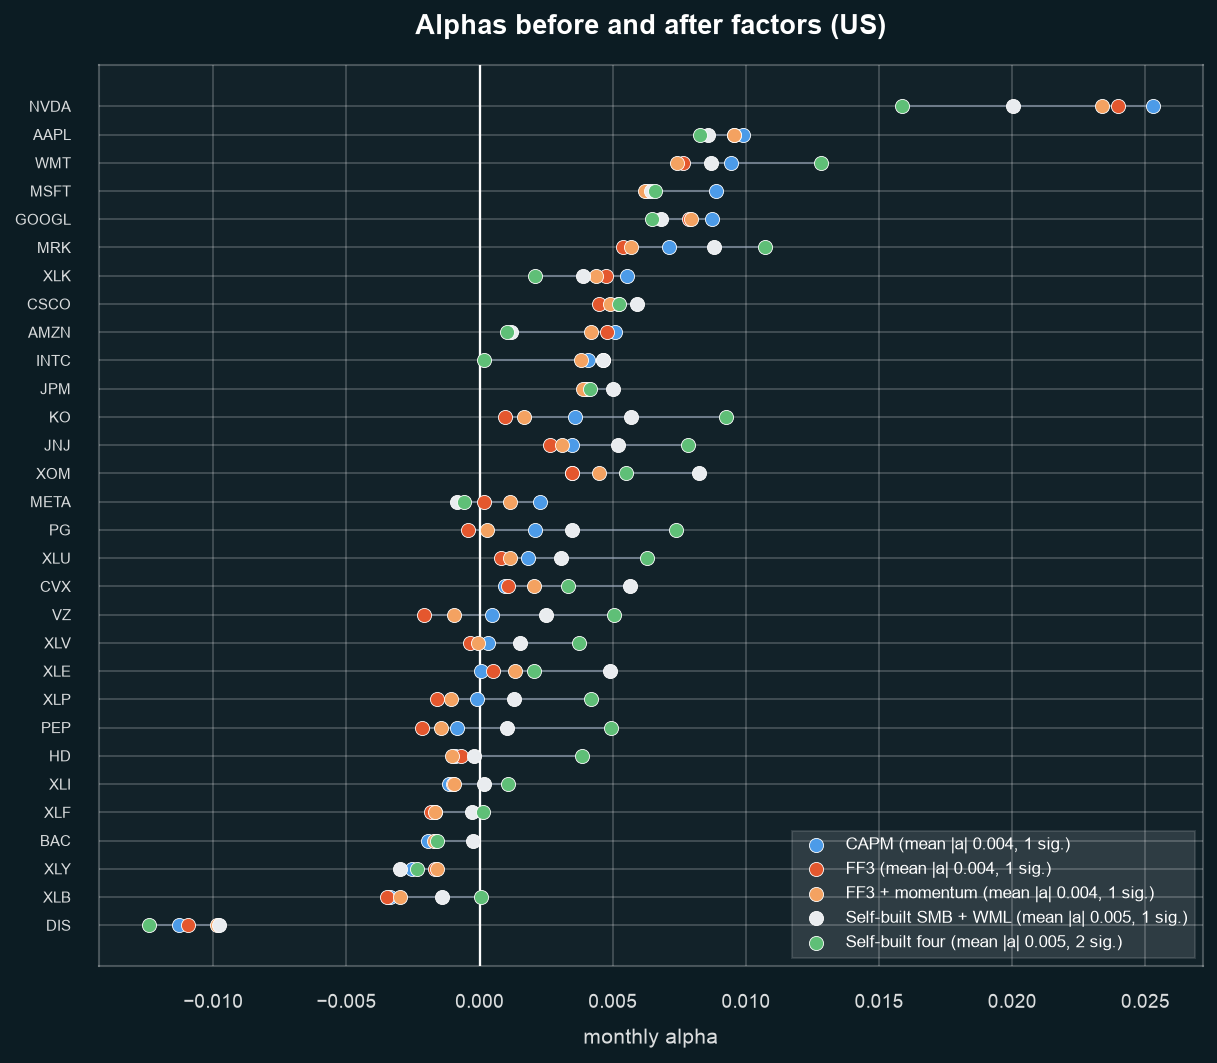

SG



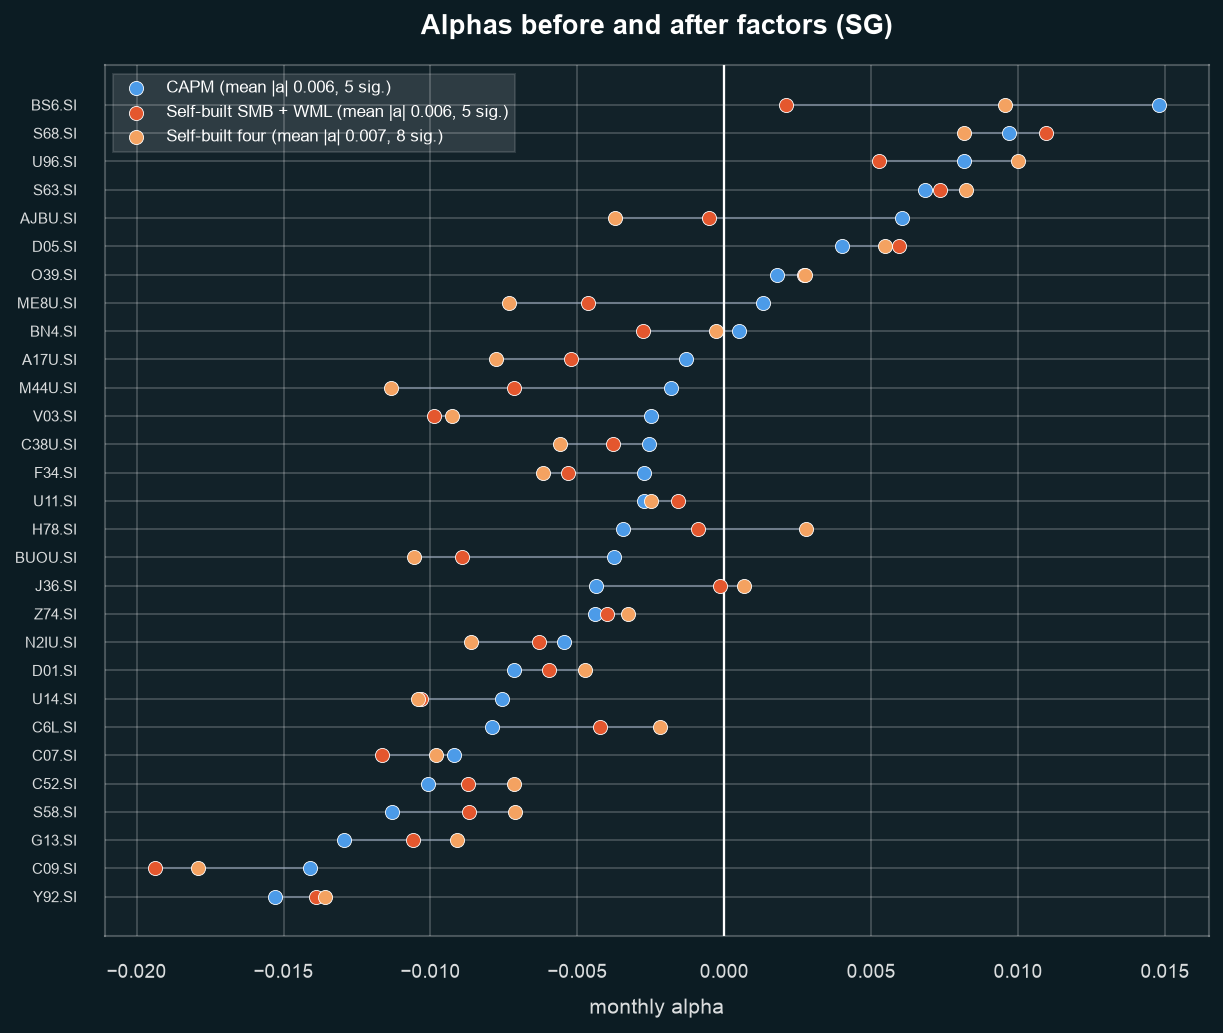

In [24]:
for u in UNIVERSES:
    print(u.upper())
    display(Image(filename=FACTORS[u].output_paths["chart"]))


**Takeaway.** In the US the CAPM already leaves little to explain: one alpha is
significant, no joint test rejects, and adding all four self-built factors barely
moves the average alpha (0.45% a month under the CAPM, 0.52% with all four) even
as the average R squared rises from 0.38 to 0.55. In Singapore the factors do not
shrink the alphas either: the average |alpha| rises from 0.63% a month to 0.71%,
and eight alphas are significant under the full set against five under the CAPM.
What the factors do is sharpen the joint test: the GRS p value falls from a
marginal 0.07 to 0.004, because they shrink the residual covariance faster than
the alphas. Size, momentum, low volatility and reversal add explanatory power
without absorbing the anomaly.


### (3d) Which anomalies survive?

The table lists every asset whose alpha is significant before or after the
factors (`|t| > 2`).


In [25]:
blocks = {}
for u in UNIVERSES:
    first, last = FACTORS[u].models[0], FACTORS[u].models[-1]
    t_first = FACTORS[u].tables[first]["t_alpha"]
    t_last = FACTORS[u].tables[last]["t_alpha"]
    flagged = (t_first.abs() > 2) | (t_last.abs() > 2)
    block = pd.DataFrame(
        {
            f"{first} alpha": FACTORS[u].alphas[first],
            f"{first} t": t_first,
            f"{last} alpha": FACTORS[u].alphas[last],
            f"{last} t": t_last,
        }
    )
    blocks[u.upper()] = block[flagged]
pd.concat(blocks).round(4)


CAPM alpha  CAPM t  Self-built four alpha  Self-built four t
   asset                                                                
US KO           0.0036  0.7939                 0.0093             2.5610
   NVDA         0.0253  2.4032                 0.0159             1.7398
   WMT          0.0094  1.8261                 0.0128             2.6820
SG A17U.SI     -0.0013 -0.3654                -0.0078            -2.4322
   BUOU.SI     -0.0038 -0.6594                -0.0105            -2.0109
   C09.SI      -0.0141 -2.7365                -0.0179            -3.6068
   C52.SI      -0.0101 -2.1852                -0.0072            -1.6411
   G13.SI      -0.0130 -2.4149                -0.0091            -1.6376
   M44U.SI     -0.0018 -0.3547                -0.0114            -2.7133
   ME8U.SI      0.0013  0.3076                -0.0073            -2.0991
   N2IU.SI     -0.0055 -1.2233                -0.0086            -2.1558
   S68.SI       0.0097  2.0371                 0.0082             1.6722
   U14.SI      -0.0076 -1.6905                -0.0104            -2.3456
   Y92.SI      -0.0153 -3.0149                -0.0136            -2.5398

**Verdict.** In the US the four factors absorb the one alpha the CAPM flagged:
NVDA's 2.5% monthly alpha falls to 1.6% (t of 2.40 to 1.74) once all four are
added, while KO and WMT move the other way and become significant, so the average
alpha is unchanged and no joint test rejects. In Singapore the individual evidence
moves in the opposite direction: eight alphas are significant under the full set
against five under the CAPM, almost all negative. ComfortDelGro, Genting and SGX
drop below significance, while six names (A17U, BUOU, M44U, ME8U, N2IU, U14)
emerge as significantly negative; City Developments and ThaiBev stay negative
throughout. The joint test strengthens sharply: the GRS p value falls from 0.07
under the CAPM to 0.004 with all four factors, because the factors shrink the
residual covariance faster than the alphas. A similar alpha per asset and a much
stronger joint rejection are not contradictory; they answer different questions.


## 6. Robustness: the market proxy


**Exhibit 3. The same assets, two market proxies.** Stage 2 re-estimated
with a value-weighted composite and with the Fama and French market factor.


In [26]:
ff3 = load_ff3()
PROXY = {
    m: run_capm_analysis(
        RETURNS[PRIMARY], universe=PRIMARY, method=m, ff3=ff3, output_dir=OUTPUT_DIR
    )
    for m in ["value_weighted", "ff_market"]
}
pd.DataFrame(
    {
        m: {
            "fitted slope": r.fit.slope,
            "theoretical slope": r.fit.theoretical_slope,
            "beta min": r.table["beta"].min(),
            "beta max": r.table["beta"].max(),
            "alphas p<0.05": int((r.table["p_alpha"] < 0.05).sum()),
            "GRS p": r.grs["p_value"],
        }
        for m, r in PROXY.items()
    }
).T.round(3)

,fitted slope,theoretical slope,beta min,beta max,alphas p<0.05,GRS p
value_weighted,0.016,0.019,0.117,1.847,2.0,0.469
ff_market,0.015,0.011,0.254,1.749,1.0,0.190



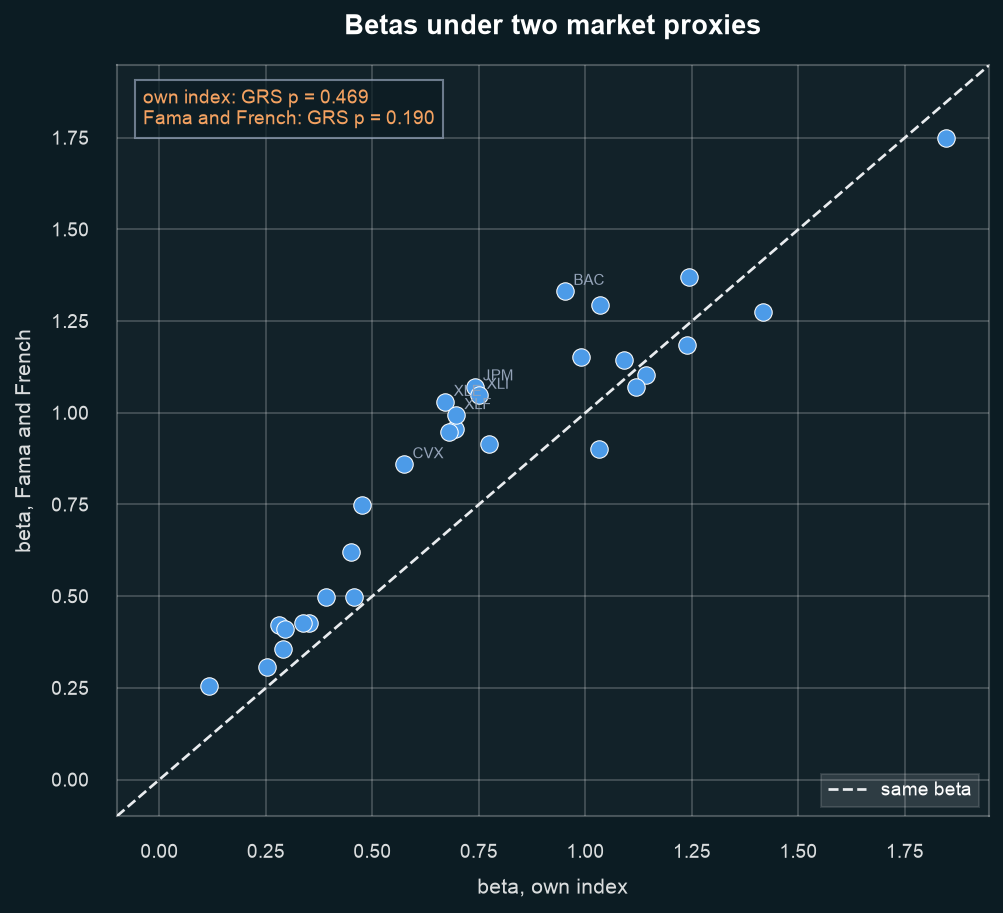

In [27]:
display(Image(filename=viz.plot_proxy_comparison(PROXY, OUTPUT_DIR / "proxy_comparison.png")))

**Takeaway.** Changing only the market proxy halves the GRS p value, from 0.47 to
0.19. The average beta rises from 0.75 to 0.88 and individual betas move by up to
0.38 even though the two proxies are strongly related; the headline number depends
on a choice we made, which is Roll's critique in miniature.


## 7. Stage 4: the memo to the investment committee

*This is the two-page memo Stage 4 asks for. It is written for a numerate but
busy reader and refers back to the exhibits rather than repeating them.*


### The recommendation: hold the index, not the tangency portfolio

The theorem tells us *how* to build the best portfolio, not *what* it is. Its
answer is the tangency portfolio, and to compute it we must supply expected
returns and a covariance matrix. Both are estimates from a finite sample, and the
tangency portfolio is unusually exposed to them: it inverts the covariance matrix,
so it places its largest bets exactly where the estimates are least stable, and it
scales those bets by expected returns, the noisiest input we have. The result is
less a portfolio than a restatement of the sample's accidents - concentrated,
long-short (it wants to short one US name by 280%), and barely recognisable from
one half of the data to the next.

That is why we would not fund it. Re-estimated each month from past data and
traded the following month (Section 7), it is the weakest rule we consider in both
markets and carries the deepest drawdown, while the index - which needs no
forecast at all - is the strongest. This is not a claim that markets are
efficient. It is the narrower and more defensible point that *our* estimates are
not good enough to support the concentrated positions the optimiser derives from
them.

So our recommendation is the value-weighted index. It is transparent, cheap,
diversified by construction, and it does not ask the committee to trust a
covariance matrix we know to be unreliable. If the committee will accept modest
estimation risk in exchange for a tilt, the sensible implementation is the
*shrunk, long-only* tangency: shrinking the inputs damps the noise, and the
no-short constraint stops the optimiser turning an estimate into a large negative
position. That keeps the spirit of the theory while refusing to bet the portfolio
on the parts of the data we trust least. What we would not do is hand the raw
tangency weights to a trader.


### Out-of-sample validation

*The table and charts below are the test the recommendation leans on. Each
strategy is re-estimated every month on an expanding window of past data and held
for the single month that follows, so no weight ever sees the return it is traded
on. The value-weighted index and 1/N need no estimation and are the benchmarks,
and the five-year training window gives the estimated portfolios every advantage a
short sample can offer - the test is generous to them, not to the index.*


In [28]:
# Out-of-sample evidence: estimate the weights every month, trade the next.
from goldman.analysis import run_out_of_sample_analysis
from goldman.data import market_excess_returns

OOS = {
    u: run_out_of_sample_analysis(
        RETURNS[u],
        universe=u,
        rf=risk_free_series(u, RETURNS[u].index),
        index_returns=market_excess_returns(RETURNS[u], universe=u),
        output_dir=OUTPUT_DIR / u,
        label=u,
    )
    for u in UNIVERSES
}
pd.concat({u: OOS[u].summary for u in UNIVERSES}).round(3)


months  ann. mean  ann. vol  Sharpe  max drawdown
us index               59.0      0.210     0.191   1.096        -0.246
   equal_weight        59.0      0.130     0.146   0.896        -0.206
   unconstrained       59.0      0.339     0.752   0.451        -0.756
   long_only           59.0      0.151     0.183   0.828        -0.314
   shrunk              59.0      0.098     0.141   0.699        -0.263
   shrunk_long_only    59.0      0.109     0.138   0.793        -0.241
sg index               59.0      0.178     0.100   1.771        -0.082
   equal_weight        59.0      0.102     0.102   1.001        -0.109
   unconstrained       59.0      0.262     0.524   0.500        -0.737
   long_only           59.0      0.171     0.145   1.176        -0.171
   shrunk              59.0      0.136     0.132   1.030        -0.204
   shrunk_long_only    59.0      0.133     0.116   1.148        -0.127

**Takeaway.** Re-estimated every month and traded forward, the index is the
strongest rule in both markets once risk is accounted for (Sharpe 1.10 in the US,
1.77 in Singapore), the raw tangency the weakest (0.45 and 0.50) with by far the
deepest drawdowns, and even the best of the estimated rules, the no-short tangency
(0.83 and 1.18), stays below the index on a risk-adjusted basis.



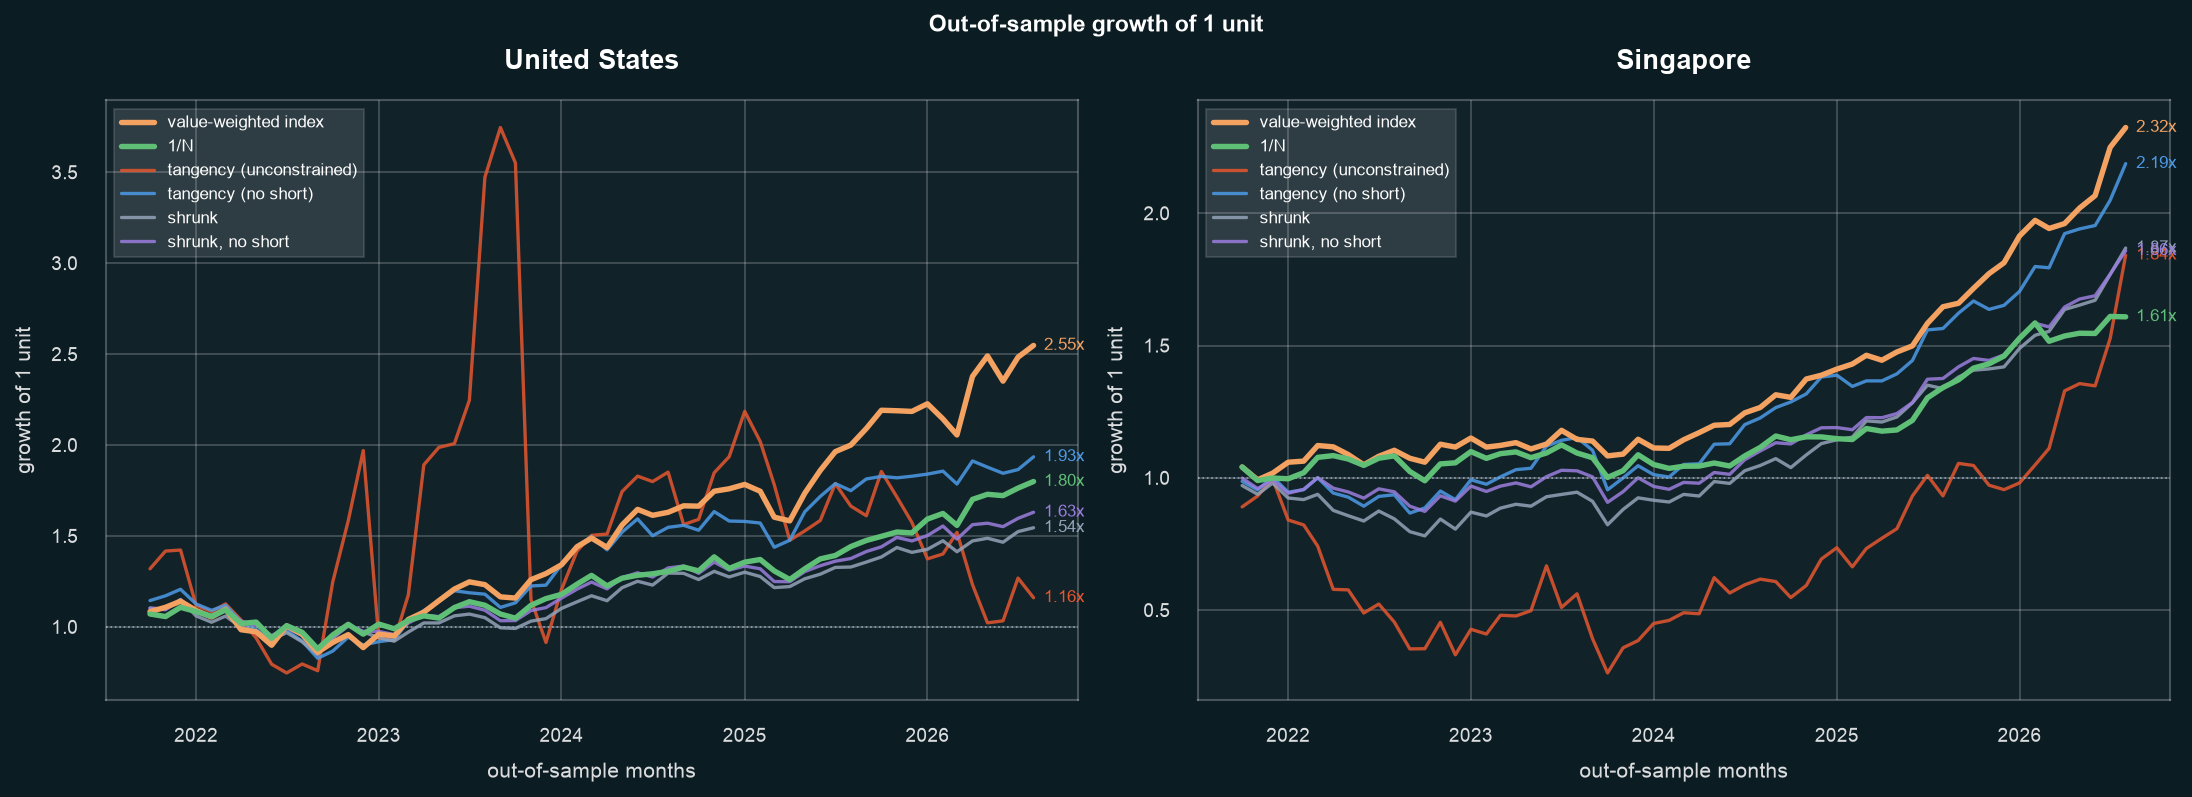

In [29]:
display(Image(filename=viz.plot_oos_growth_paired(
    {u: OOS[u].growth for u in UNIVERSES}, OUTPUT_DIR / "oos_growth_paired.png"
)))


**Takeaway.** The 59 out-of-sample months separate the rules. In the US the
index compounds to the largest gain (2.55 times the starting value) while the
unconstrained tangency ends near where it began (1.16x), after a spike to almost
4x and a fall back to earth; in Singapore the index also compounds to the largest
gain (2.32x), ahead of the no-short tangency (2.19x), which carries about 45% more
volatility. Across both markets the unconstrained tangency is the worst on a
risk-adjusted basis and draws down the most, about -76% in the US and -74% in
Singapore - losses the optimiser never chose, but estimation error delivered.



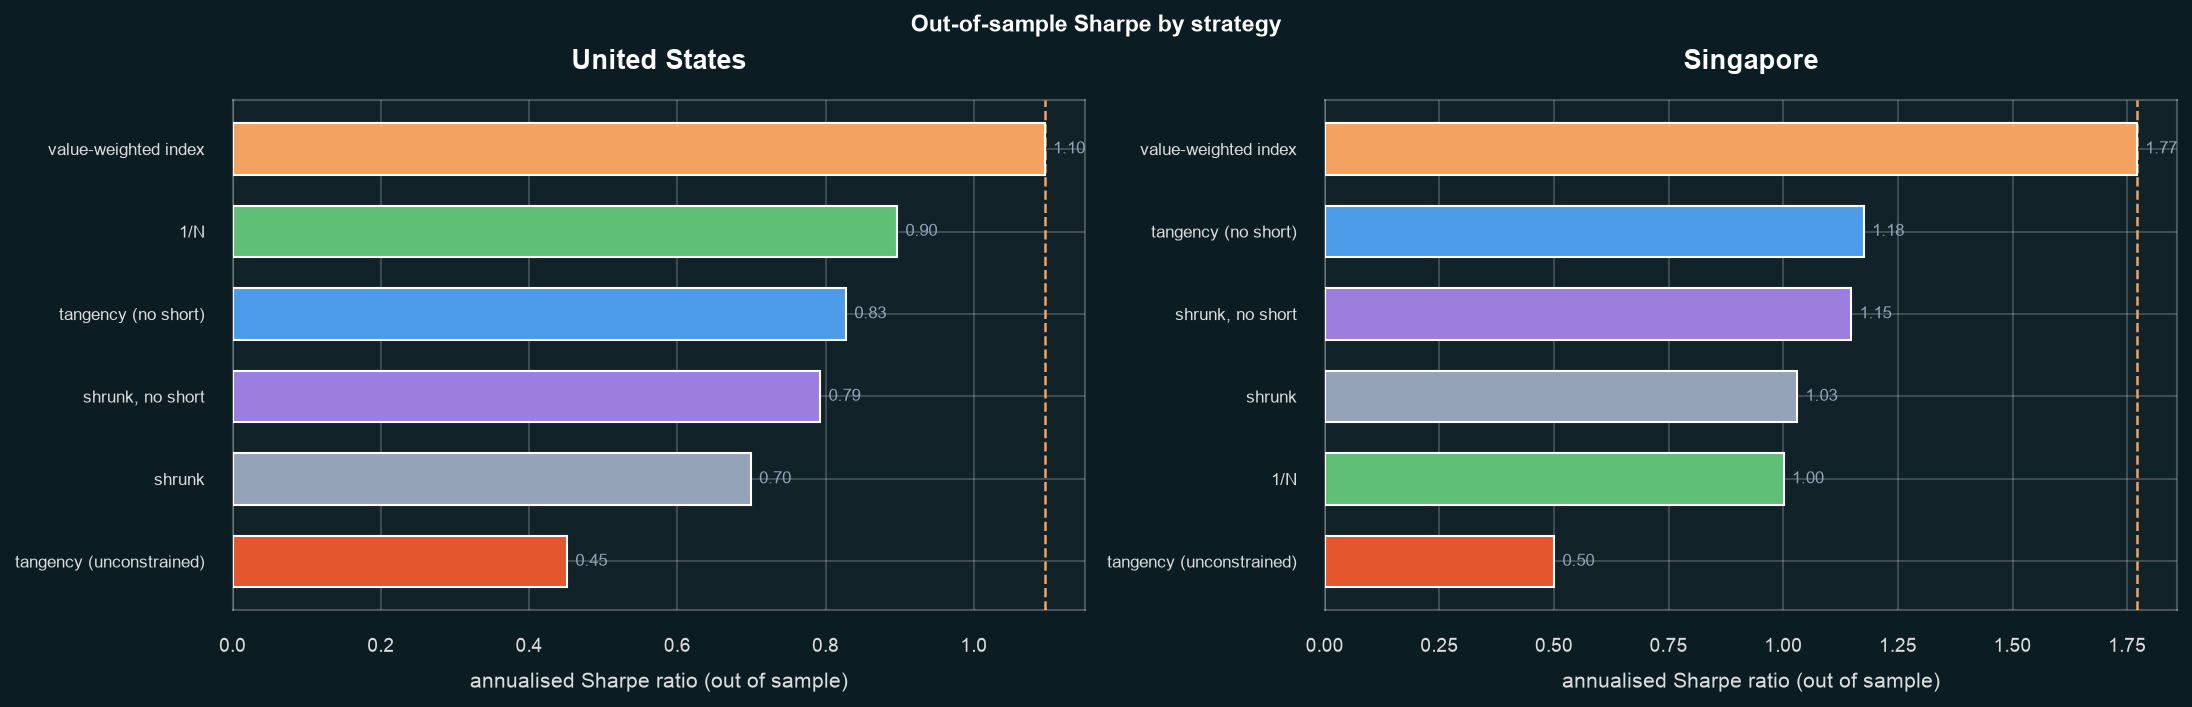

In [30]:
display(Image(filename=viz.plot_oos_sharpe_paired(
    {u: OOS[u].summary for u in UNIVERSES}, OUTPUT_DIR / "oos_sharpe_paired.png"
)))


**Verdict.** Rank the rules by Sharpe and both markets agree at the ends: the
index first (1.10 in the US, 1.77 in Singapore) and the raw tangency last (0.45
and 0.50). In between, the no-short tangency is the best of the estimated rules
(0.83 and 1.18), with its shrunk version close behind (0.79 and 1.15), yet both
stay short of the index. The constrained and shrunk variants do cut the tail risk
sharply - the worst drawdown falls from -76% to between -24% and -31% in the US,
and from -74% to between -13% and -20% in Singapore - but none of them beats the
estimation-free benchmark once risk is priced in. That gap
is the price of estimating the inputs instead of inheriting them from the market,
and it is why the memo recommends the index.


### Why we did not keep hunting for factors

The obvious response to a disappointing factor result is to go looking for more
factors. We do not think that would change the answer here, and the reason is the
universe rather than the search.

**The index is itself the concentrated bet.** The US universe is 21 mega-caps plus
nine sector ETFs, and Singapore is roughly 29 large STI names. A value-weighted
index over either is not a diversified average of the assets but a wager on the
largest few, and it inherits their winning run: the largest name carries about a
sixth of the index and the top five together more than half (chart below). Over
2016-2026, the most concentrated mega-cap US market in modern history, almost any
factor tilt is at heart a bet against that concentration. Size tilts overweight
smaller names; volatility and momentum tilts move exposure around the same handful
of leaders. In a decade when the leaders compounded, deviating from the cap
weights is what loses, and none of the tilts in Sections 1 to 3 escapes that
arithmetic.

**Survivorship pre-loads the winners.** Both universes are today's members carried
back to 2016 (Section 2), so the firms that failed or were acquired are simply
absent. That is fatal for cross-sectional work: a factor sort needs both a winner
leg and a loser leg, and we have systematically deleted the losers. The measured
spread between the legs is compressed or reversed, and the surviving estimates are
biased optimistically at the same time. The self-built Singapore size factor in
Section 5 is the clean example - its "small" leg is large by any real standard, so
it is a weak proxy for the thing it names.

**Thirty assets is too few independent bets.** A signal on 30 names, re-formed
monthly over 119 months, gives only a few dozen meaningful bets per leg and a
handful of regime episodes. That is power enough to see the market factor and the
SML clearly, because they use the whole panel, but not enough to resolve a factor
whose true premium is a fraction of a percent a month. The wide intervals in every
alpha exhibit in Sections 4 and 5 are that lack of power, not proof that no effect
exists.

The honest conclusion is not that we failed to find the right factor, but that this
universe is the wrong instrument with which to look. The index wins because in this
sample it *is* the concentration, and concentration is what paid. Testing whether
size, value, momentum or volatility are priced needs a broad cross-section -
mid- and small-caps, delisted names, a longer window spanning different regimes -
none of which our data provide. After the concentration chart below, we run momentum on the one
such data set we can reach without new sources: Ken French's ten US industries
since 1964.



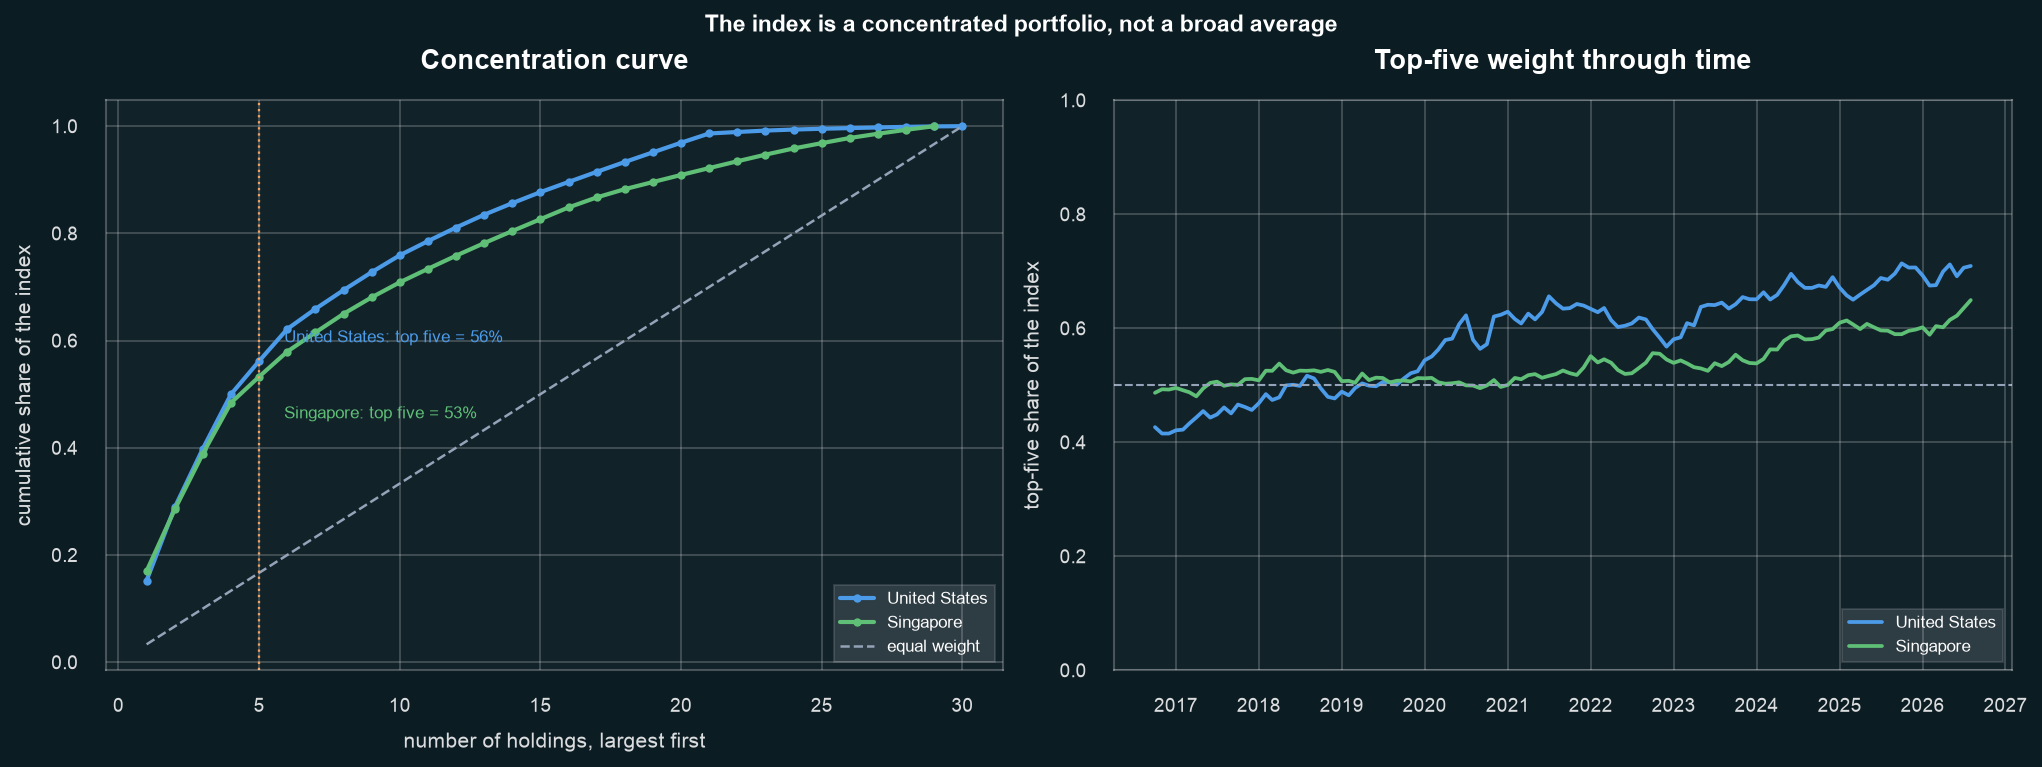

In [31]:
from goldman.data import load_value_weights

CONCENTRATION_WEIGHTS = {
    u: load_value_weights(universe=u, assets=RETURNS[u].columns, dates=RETURNS[u].index)
    for u in UNIVERSES
}
display(Image(filename=viz.plot_index_concentration(
    CONCENTRATION_WEIGHTS, OUTPUT_DIR / "index_concentration.png"
)))


**Takeaway.** The "market" is a concentrated portfolio, not a broad average:
the single largest name carries about a sixth of the index in both markets and
the top five together 53% in Singapore and 56% in the US (left panel), and that concentration is
persistent rather than a one-month accident (right panel). A factor tilt that
shifts weight down the capitalisation ranking is therefore a bet against the very
names that produced the return, which is why every diversified-looking alternative
lost to the index in Section 7. That is a property of this universe, not a verdict
on the factors.


### Industry momentum: the test our universe cannot run

Momentum is the self-built factor we can rerun on a better instrument. Ken French's ten
value-weighted US industry portfolios hold every CRSP stock, including the firms
that later failed or were taken over, so they carry no survivorship bias, and
they start in July 1963. The rule is Moskowitz and Grinblatt's (1999) industry
momentum, which is our WML applied to industries: each month we rank the ten
industries on their return from t-12 to t-2, go long the best three and short the
worst three, equal-weighted, and hold for one month. That gives 746 months from
July 1964 to August 2026.

We test it against the CAPM and the Fama and French three factors, compare it
with Ken French's stock-level momentum factor, and charge 50 basis points per unit
of turnover. The table splits the sample at the decade our own data cover, and
its last column runs the same rule on our 30 US assets, which is the WML of
Section 5.


In [32]:
from goldman.analysis import build_industry_momentum, industry_momentum_report
from goldman.data import load_long_history

LONG = load_long_history()
IND_MOM, IND_TRADED = build_industry_momentum(LONG.industries)
IND_PERIODS = {
    "1964-07 to 2026-08": ("1964-07", "2026-08"),
    "1964-07 to 2016-09": ("1964-07", "2016-09"),
    "2016-10 to 2026-08 (ours)": ("2016-10", "2026-08"),
}
IND_TABLE = industry_momentum_report(IND_MOM, IND_TRADED, LONG.factors, periods=IND_PERIODS)
# The same rule on our 30 US assets: 30 // 3 = 10 names per leg, which is WML.
US_WML, US_TRADED = build_industry_momentum(RETURNS["us"])
IND_TABLE.loc["our 30 US assets, WML"] = industry_momentum_report(
    US_WML, US_TRADED, LONG.factors, periods={"ours": ("2016-10", "2026-08")}
).loc["ours"]
IND_TABLE[[
    "months", "ann. mean", "t(mean)", "Sharpe", "CAPM alpha (ann.)", "t(CAPM alpha)",
    "FF3 alpha (ann.)", "t(FF3 alpha)", "corr with Mom", "turnover / month",
    "net mean at 50bp (ann.)", "break-even cost (bp)",
]].astype(float).round(3).T

period,1964-07 to 2026-08,1964-07 to 2016-09,2016-10 to 2026-08 (ours),"our 30 US assets, WML"
months,746.000,627.000,119.000,107.000
ann. mean,0.038,0.035,0.052,0.037
t(mean),2.184,1.954,0.977,0.668
Sharpe,0.277,0.270,0.310,0.224
CAPM alpha (ann.),0.040,0.038,0.039,0.049
t(CAPM alpha),2.264,2.105,0.716,0.869
FF3 alpha (ann.),0.049,0.048,0.028,0.039
t(FF3 alpha),2.797,2.647,0.521,0.681
corr with Mom,0.720,0.770,0.533,0.722
turnover / month,0.821,0.813,0.863,0.731



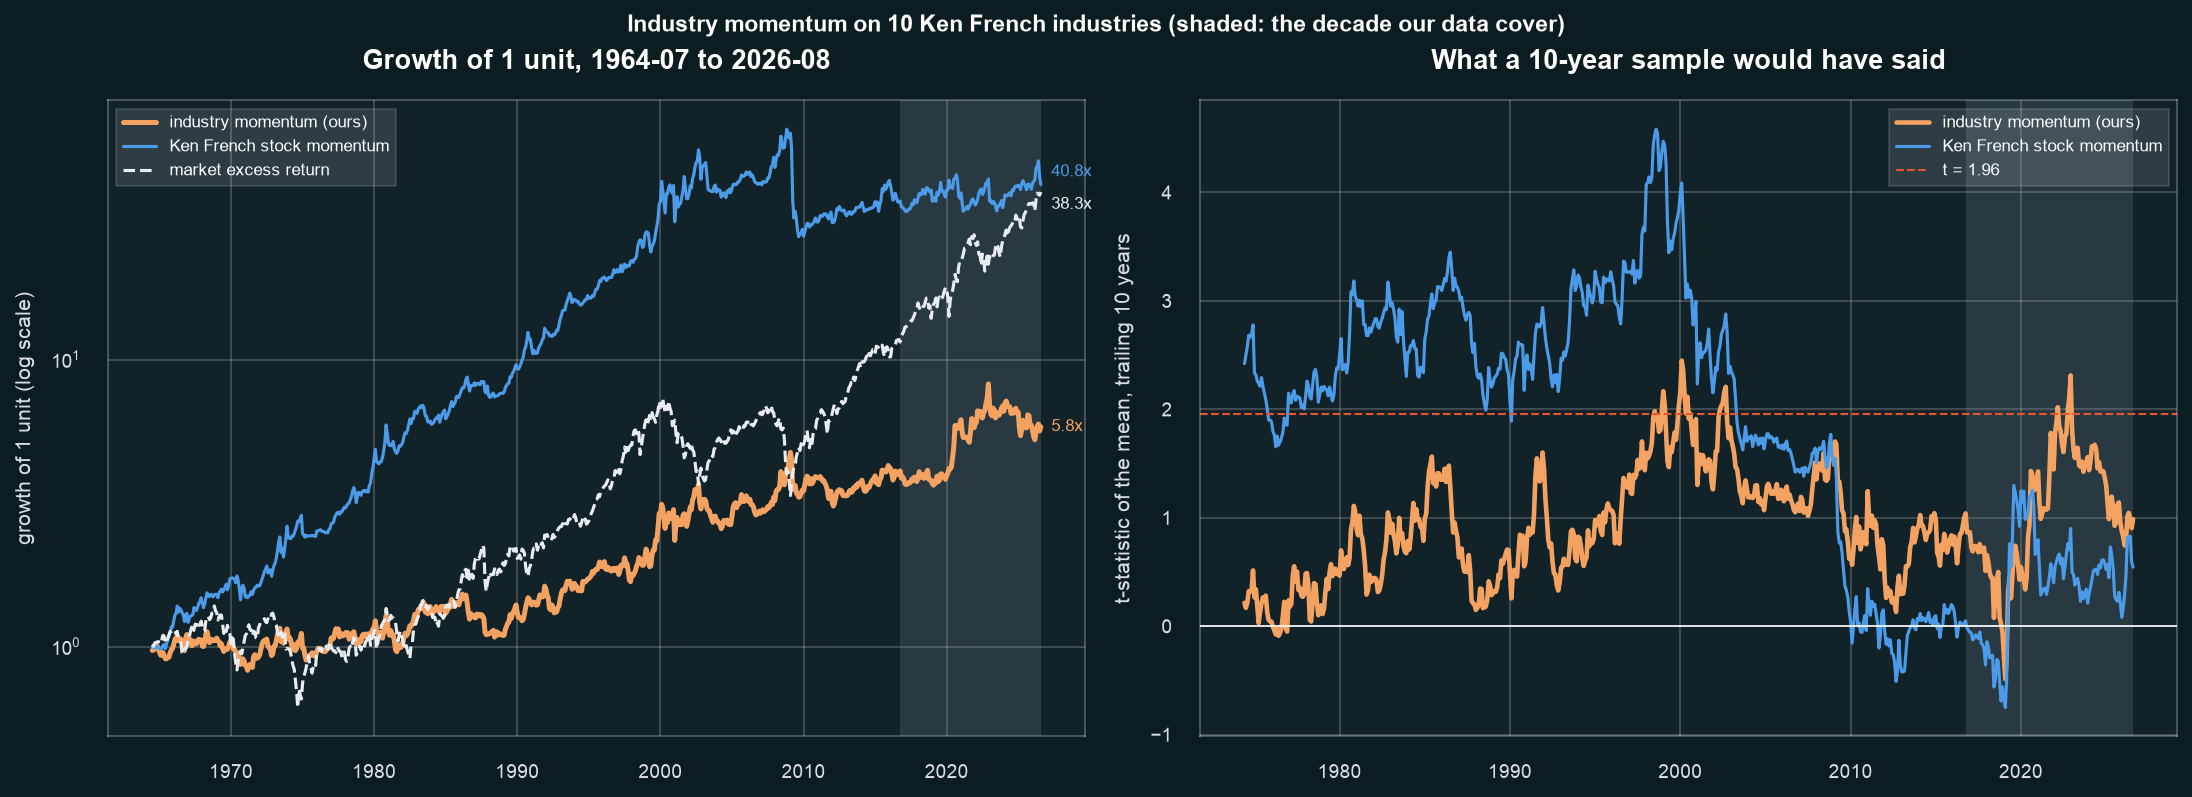

In [33]:
ind_factors = LONG.factors.copy()
ind_factors.index = ind_factors.index.to_timestamp()
ind_panel = ind_factors[["Mom", "Mkt-RF"]].reindex(IND_MOM.index).assign(IndMom=IND_MOM)
display(Image(filename=viz.plot_industry_momentum(
    ind_panel[["IndMom", "Mom", "Mkt-RF"]],
    OUTPUT_DIR / "industry_momentum.png",
    highlight=("2016-10", "2026-08"),
)))

**Takeaway.** On a broad, survivor-free cross-section, momentum is priced. Over
746 months industry momentum earns 3.8% a year (t = 2.2), with alphas of 4.0%
against the CAPM (t = 2.3) and 4.9% against the three Fama and French factors
(t = 2.8), and it correlates 0.72 with Ken French's stock-level momentum, so it is
the same effect seen through industries. Momentum was no weaker in our decade:
the Sharpe ratio over 2016-10 to 2026-08 is 0.31, against 0.28 over the full sample.
What the decade lacks is evidence. Over 119 months the same premium has a t of
1.0, and the right panel shows that the ten-year mean was positive in 98% of
trailing windows since 1974 but cleared t = 1.96 in only 3% of them. At a Sharpe
ratio of 0.28 the mean needs about 52 years of data to reach t = 2. Our 30-asset
WML (Sharpe 0.22 over 107 months, t = 0.7) therefore says little about momentum
either way.

Two further points temper the result. Ken French's stock-level factor cleared
t = 1.96 in 94% of the ten-year windows ending before 2004, but since 2010 its
ten-year t has stayed between -0.75 and 1.30, so the weak momentum in our sample
is partly a weak decade for momentum and not only a weak universe. And the premium
is hard to keep: the strategy turns over 82% of its gross position a month, so at
50 basis points a trade it earns -1.1% a year, and it breaks even only at a cost
of 38 basis points. Momentum is priced in the broad US market, but a fund paying
realistic costs would not have captured it with this rule.


### Roll's critique: we test the proxy, not the CAPM

A CAPM test is never run against "the market". It is run against a stand-in we
choose, and the model requires that stand-in to be mean-variance efficient. Our
value-weighted index and Ken French's market factor are two proxies for the same
US market, but they are not the same portfolio. Swapping one for the other on the
same assets (Section 6) leaves the story intact and moves the evidence: individual
betas shift by up to 0.38, the alphas on some names move enough to change which
ones look significant, and the GRS p value halves. The direction of the finding is
stable; its strength is not.

That sensitivity is itself the finding. It means we cannot say the CAPM is true or
false from this exercise - only whether a particular proxy passes. Roll's critique
stops being an abstract caveat and becomes a description of our own results: the
number we report depends on a choice we made, and another reasonable choice would
have told a different story.


**Exhibit 4. The same assets, two market proxies.** Betas (left) and alphas
(right) estimated with our value-weighted index against the Fama and French
market factor; distance from the dashed line is how much the estimate depends on
the proxy.



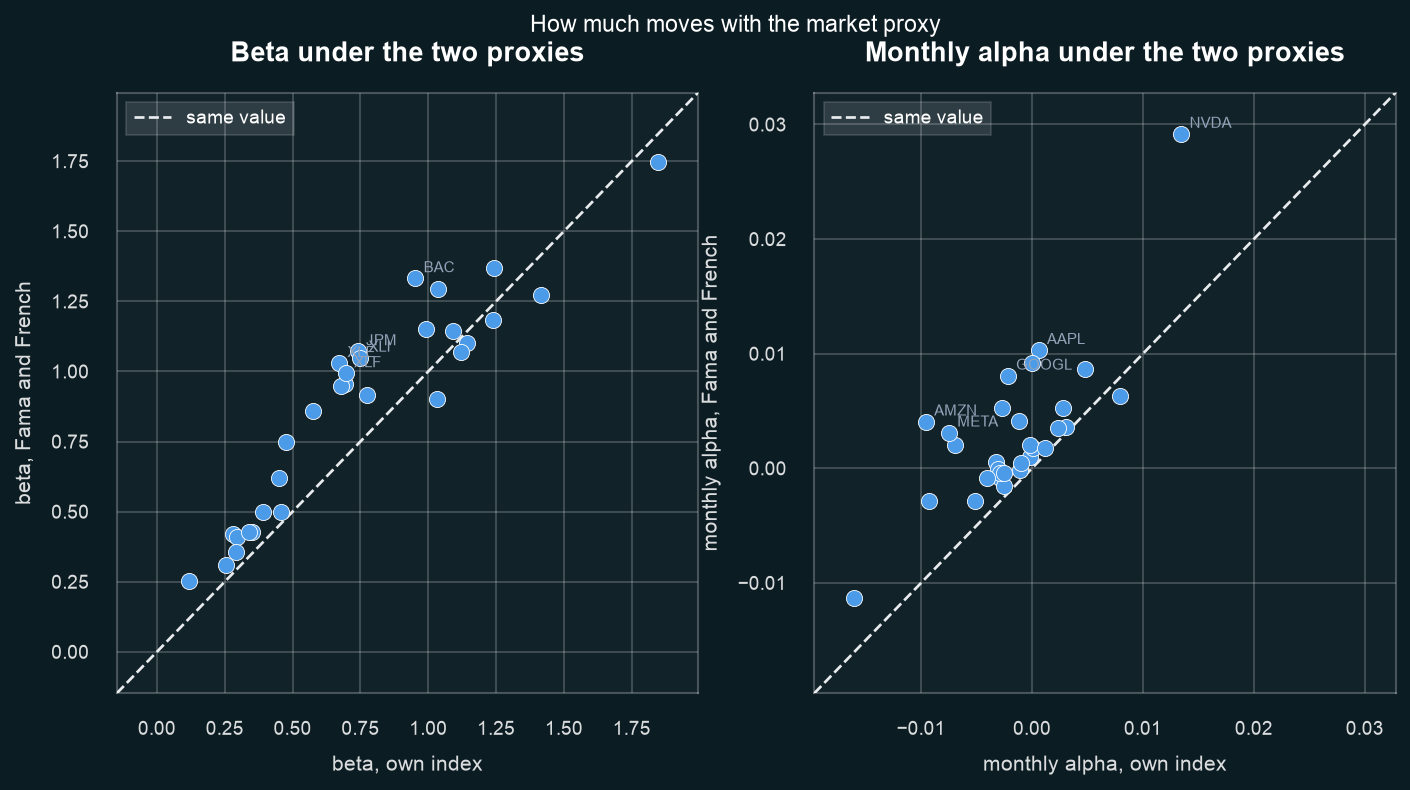

In [34]:
display(Image(filename=viz.plot_proxy_shift(
    PROXY, OUTPUT_DIR / "proxy_shift.png"
)))


### How much confidence should we place in individual alphas?

We keep each model's returns, factors and dates fixed and change only its
standard errors using [Newey and West (1987), *Econometrica* 55, 703-708](https://doi.org/10.2307/1913610).
HAC allows changing residual volatility and dependence across months. Three
monthly lags is our baseline; zero and six are sensitivity checks, not optimised choices.

**Exhibit 5. Individual alphas significant at 5%.** OLS uses ordinary standard
errors; HAC(0) allows changing volatility only, while HAC(3/6) also allows serial
dependence. Compare across a row: Stage 2 uses local indices; Stage 3 uses the
Fama-French market factor for the US and the local index for Singapore.


In [35]:
from goldman.analysis.sensitivity import hac_lag_sensitivity

# Reuse the model panels and RF conventions already used in Stages 2 and 3.
# HAC changes inference only: the assertions ensure that OLS estimates agree.
INFERENCE = {}
for u in UNIVERSES:
    rf = risk_free_series(u, RETURNS[u].index)
    market = market_excess_returns(RETURNS[u], universe=u, method=CAPM[u].method, rf=rf)
    stage2 = hac_lag_sensitivity(
        RETURNS[u], {"CAPM (local index)": market.to_frame("Mkt-RF")}, rf=rf
    )
    np.testing.assert_allclose(
        stage2.tables.loc[("CAPM (local index)", 3), ["alpha", "beta_Mkt-RF", "p_alpha"]],
        CAPM[u].table[["alpha", "beta", "p_alpha"]], rtol=1e-9, atol=1e-12,
    )
    np.testing.assert_array_equal(stage2.sample, RETURNS[u].index)
    INFERENCE[("Stage 2", u)] = stage2

    stage3 = hac_lag_sensitivity(RETURNS[u], FACTOR_MODELS[u], rf=rf)
    np.testing.assert_array_equal(stage3.sample, FACTORS[u].sample)
    for name in FACTOR_MODELS[u]:
        reference = FACTORS[u].tables[name]
        np.testing.assert_allclose(
            stage3.tables.loc[(name, 3), reference.columns], reference,
            rtol=1e-9, atol=1e-12,
        )
    INFERENCE[("Stage 3", u)] = stage3

INFERENCE_DIR = OUTPUT_DIR / "inference_robustness"
INFERENCE_DIR.mkdir(parents=True, exist_ok=True)
summary_rows, detail_frames, flag_rows = [], [], []
for (stage, u), result in INFERENCE.items():
    details = result.tables.reset_index()
    details.attrs = {}
    details.insert(0, "universe", u)
    details.insert(0, "stage", stage)
    detail_frames.append(details)
    pd.Series(result.sample, name="Date").to_csv(
        INFERENCE_DIR / f"{stage.lower().replace(' ', '_')}_{u}_sample.csv", index=False
    )
    for model in result.summary.index.get_level_values("model").unique():
        table = result.tables.loc[model]
        base = table.loc[3]
        summary_rows.append({
            "stage": stage, "universe": u, "model": model,
            "assets": len(base), "months": len(result.sample),
            "start": result.sample[0].strftime("%Y-%m"),
            "end": result.sample[-1].strftime("%Y-%m"),
            "OLS": int(base.significant_alpha.sum()),
            **{f"HAC({lag})": int(table.loc[lag].significant_alpha_hac.sum()) for lag in (0, 3, 6)},
        })
        for asset in base.index:
            p = {lag: float(table.loc[(lag, asset), "p_alpha_hac"]) for lag in (0, 3, 6)}
            flag_rows.append({
                "stage": stage, "universe": u, "model": model, "asset": asset,
                "alpha_monthly": base.loc[asset, "alpha"],
                "OLS p": base.loc[asset, "p_alpha"],
                **{f"HAC({lag}) p": p[lag] for lag in (0, 3, 6)},
                "OLS significant": bool(base.loc[asset, "significant_alpha"]),
                "HAC(3) significant": bool(base.loc[asset, "significant_alpha_hac"]),
                "lag_sensitive": len({value < 0.05 for value in p.values()}) > 1,
                "changed_at_3": bool(base.loc[asset, "significant_alpha"])
                    != bool(base.loc[asset, "significant_alpha_hac"]),
            })

INFERENCE_SUMMARY = pd.DataFrame(summary_rows)
INFERENCE_DETAILS = pd.concat(detail_frames, ignore_index=True)
INFERENCE_FLAGS = pd.DataFrame(flag_rows)
INFERENCE_SUMMARY.to_csv(INFERENCE_DIR / "inference_summary.csv", index=False)
INFERENCE_DETAILS.to_csv(INFERENCE_DIR / "inference_details.csv", index=False)
INFERENCE_FLAGS.to_csv(INFERENCE_DIR / "inference_flags.csv", index=False)

import hashlib
import importlib.metadata
import json

from goldman.config import DATA_DIR

# Record input fingerprints and inference conventions beside the generated tables.
input_files = [
    "prices_us_monthly.csv", "prices_sg_monthly.csv", "ff3_monthly.csv",
    "value_weights_us.csv", "value_weights_sg.csv", "rf_sg_monthly.csv",
]
manifest = {
    "significance": 0.05, "hac_lags": [0, 3, 6], "baseline_hac_lag": 3,
    "kernel": "Bartlett", "covariance_correction": "T/(T-p)",
    "p_value_reference": "Student-t(T-p), finite-sample approximation",
    "alpha_units": "monthly decimal", "multiple_testing_adjustment": None,
    "grs_recomputed_with_hac": False,
    "samples": INFERENCE_SUMMARY[[
        "stage", "universe", "model", "assets", "months", "start", "end"
    ]].to_dict("records"),
    "us_rf_fallback_months": [
        date.strftime("%Y-%m") for date in RETURNS["us"].index
        if date.to_period("M") not in load_ff3().index
    ],
    "data_sha256": {
        name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
        for name in input_files
    },
    "versions": {
        package: importlib.metadata.version(package)
        for package in ("numpy", "pandas", "scipy", "matplotlib")
    },
}
_ = (INFERENCE_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")

# Keep the memo compact; full dates, estimates and p-values are in the CSVs.
display(
    INFERENCE_SUMMARY.replace({"universe": {"us": "US", "sg": "SG"}})
    .set_index(["stage", "universe", "model"])
    .rename_axis(["Stage", "Market", "Model"])
    [["months", "OLS", "HAC(0)", "HAC(3)", "HAC(6)"]]
    .rename(columns={"months": "Months"})
)


Months  OLS  HAC(0)  HAC(3)  HAC(6)
Stage   Market Model                                                    
Stage 2 US     CAPM (local index)       119    2       2       2       2
Stage 3 US     CAPM                     106    1       1       1       3
               FF3                      106    1       2       2       4
               FF3 + momentum           106    1       1       2       2
               Self-built SMB + WML     106    1       1       1       2
               Self-built four          106    2       3       5       6
Stage 2 SG     CAPM (local index)       119    3       4       4       4
Stage 3 SG     CAPM                     107    5       4       3       5
               Self-built SMB + WML     107    5       5       3       6
               Self-built four          107    8       7       8       8

In [36]:
from IPython.display import Markdown

# Generate the numerical takeaway from this run, so it cannot retain old counts.
sg_counts = INFERENCE_SUMMARY.query("stage == 'Stage 3' and universe == 'sg'").set_index("model")
sg_capm = sg_counts.loc["CAPM"]
sg_factors = sg_counts.loc["Self-built four"]
comparisons = "; ".join(
    f"{int(sg_capm[column])} to {int(sg_factors[column])} under {column}"
    for column in ("OLS", "HAC(3)", "HAC(6)")
)
us_flags = INFERENCE_FLAGS.query("stage == 'Stage 3' and universe == 'us' and asset == 'NVDA'")
nvda_3 = int((us_flags["HAC(3) p"] < 0.05).sum())
nvda_6 = int((us_flags["HAC(6) p"] < 0.05).sum())
sg_direction = (
    "Adding factors does not consistently reduce the significant-alpha count."
    if any(sg_factors[c] >= sg_capm[c] for c in ("OLS", "HAC(0)", "HAC(3)", "HAC(6)"))
    else "Adding factors reduces the significant-alpha count at every checked setting."
)
INFERENCE_TAKEAWAY = (
    "**Takeaway.** Singapore's Stage-3 counts before and after adding all four self-built factors are "
    + comparisons + ". " + sg_direction
    + f" In the US, NVDA is significant in {nvda_3} of {len(us_flags)} Stage-3 models at three lags"
    + f" and {nvda_6} at six. Equal counts can hide different assets. "
    + "For the committee, this qualifies confidence in individual alpha signals; "
    + "it does not provide a new allocation recommendation."
)
_ = (INFERENCE_DIR / "memo_takeaway.md").write_text(INFERENCE_TAKEAWAY + "\n")
display(Markdown(INFERENCE_TAKEAWAY))


**Takeaway.** Singapore's Stage-3 counts before and after adding all four self-built factors are 5 to 8 under OLS; 3 to 8 under HAC(3); 5 to 8 under HAC(6). Adding factors does not consistently reduce the significant-alpha count. In the US, NVDA is significant in 4 of 5 Stage-3 models at three lags and 2 at six. Equal counts can hide different assets. For the committee, this qualifies confidence in individual alpha signals; it does not provide a new allocation recommendation.

**Limits.** With 106-119 monthly observations, HAC p-values are approximate
and unadjusted for multiple testing. These individual tests neither replace
the joint GRS test nor establish trading profits. Alphas and portfolio returns
are unchanged; data errors, benchmark timing and survivorship bias remain outside
what this check can fix.


### The result we trust least

The self-built Singapore size factor. It is a long-short spread over roughly 29
large, liquid STI names, so the "small" leg is large by any real standard, and it
is built from the same returns it is asked to explain, so part of its
explanatory power is mechanical rather than economic. It is a legitimate
robustness result - it raises the R squared and sharpens the joint test the way a
genuine factor would - but we would not claim it as evidence that size is priced in
Singapore. The US result is the one we
trust most precisely because it is dull: against a value-weighted index the market
prices these mega-caps about as well as the CAPM says it should, and the factors
have almost nothing left to do.


## Appendix

### A. Contribution statement

Contributions were roughly equal. Each member is listed with the work they
owned; all members reviewed the final report and can defend every number in it.

| Member | Student ID | Contribution |
|---|---|---|
| **Rahul Thaker** | A0294733W | Project scaffold and reproducible pipeline; point-in-time market caps and value weights; US and Singapore data loaders, risk-free proxies and the SORA build; Stage 1 portfolio choice, estimation-error analysis and no-short/shrinkage robustness; Stage 2 CAPM and empirical SML; Stage 3 self-built size, momentum, low-volatility and reversal factors and the factor-model comparison; paired-market visualisation; Stage 4 memo and out-of-sample validation; report writing, editing and PR integration. |
| **Yi-Kai Tsai** | A0355345B | The robustness analysis: built the opt-in Newey-West (HAC) covariance machinery and used it to re-test every Stage-2 and Stage-3 alpha at 0, 3 and 6 monthly lags, quantifying how the standard-error choice changes which individual alphas survive (Exhibit 5); integrated the robustness results into the report and reviewed the draft against the project requirements. |
| **Aryan Sethi** | A0330514U | Singapore data cleaning: rebuilt every SGX total-return series and point-in-time market cap from the daily cache, the SGX corporate actions and month-end USD/SGD, documenting each correction with its source; built and compared the custom factors across both markets, including the industry-momentum factor on 60 years of Ken French US industries with its premium, alphas, turnover and break-even cost. |
| **Deepank Dewan** | A0357157W | Alternative-factor exploration for Stage 3; the US and Singapore factor-analysis notebook; report review. |

**Signed:** Rahul Thaker · Yi-Kai Tsai · Aryan Sethi · Deepank Dewan


### B. Use of AI tools

AI models including Claude, ChatGPT and Deepseek were used for assistance with
code generation and debugging. Every number, citation and claim in this report
was checked by us, and we take responsibility for it.

### C. Data sources

- **US prices** - Yahoo Finance adjusted closes (splits and dividends), a total-return proxy, audited against raw closes and dividends (`scripts/audit_yahoo_prices.py`).
- **Singapore prices and corporate actions** - SGX historical prices and corporate-action notices, with Yahoo daily closes and dividends; rebuilt by `goldman.data.cleaning`. Details in `data/cleaning_report_sg.txt` and `data/corporate_actions_sg.csv`.
- **Risk-free rates** - US: the Fama-French `RF` column. Singapore: the month-over-month change in the MAS compounded SORA Index (`data/rf_sg_monthly.csv`).
- **Factors and long-run benchmarks** - Ken French Data Library: FF3 and `RF`, momentum (`Mom`), and the 10 value-weighted US industry portfolios.
- **FX** - Yahoo `SGD=X` month-end USD/SGD, for the USD-quoted Singapore listings.
- **Share counts** - Yahoo Finance and company filings, for point-in-time market caps.


### D. Data cleaning and construction

We assemble two ten-year monthly panels from the committed raw files, and the
cleaning - not the regressions - is where most of the data work sits. Each
universe holds 120 month-end prices, i.e. 119 monthly returns from October 2016
to August 2026: 30 US names (21 mega-caps plus 9 SPDR sector ETFs), and 30 SGX
listings of which 9CI is dropped for a 60-month history, leaving 29. Both panels
are today's members backfilled, so they carry the survivorship bias the handout
asks us to flag: failed firms are missing, average returns are biased upward,
and the CAPM looks better than it is.

**Point-in-time value weights.** The market benchmark is a value-weighted
portfolio, so its weights must not see the future. For each month we compute
`market cap(t) = split-unadjusted close(t) x shares outstanding(t)`,
forward-fill shares from their report dates only, and carry the earliest known
count back where a provider has no early history. Yahoo's own `Close` is
retroactively divided by every later split, so we first undo each split to
recover the true price. The weight panel is long
(`asset, date, market_cap, weight`), and every month uses only a share count
that was known by then.

**US prices.** Yahoo adjusted closes (splits and dividends), used as a
total-return proxy and audited by rebuilding each series from raw closes plus
dividends: the two agree within 0.11% in every month, with no mis-adjusted
ex-date.

**Risk-free rate.** The US rate is the Fama-French `RF` column. For
Singapore we build the rate ourselves from MAS's daily "Domestic Interest
Rates" export (the raw download is committed at
`data/raw/mas/domestic_interest_rates.csv`): after reconstructing dates from
the export's split year/month/day columns, the exact one-month risk-free
return is the month-over-month change in the compounded SORA Index,
`RF_t = SORA_Index(month-end_t) / SORA_Index(month-end_{t-1}) - 1`, which
compounds the daily overnight SORA at actual/365 (we checked this against the
export's daily quotes to ~1e-11). We deliberately do not average the
annualised daily quotes and divide by 12 - that first-order approximation is
not exact - so the compounded index is used directly. The resulting monthly
series (2005-08 to 2026-09, `data/rf_sg_monthly.csv`) is committed with its
provenance in `data/rf_sg_monthly.source.txt`; if the file is ever missing the
loader warns and falls back to a documented constant rather than silently
borrowing the US rate.

**Singapore - a rebuild, not a download.** Yahoo's adjusted close is wrong for
several SGX names, so we do not use it. For each ticker we follow Yahoo's
unadjusted daily close and dividends next to SGX's own last-traded price, and
rebuild the total-return series and caps ourselves:

- *Wrong dividend currency.* ThaiBev (Y92) had every pre-2024 dividend adjusted
  using the baht amount as if it were SGD, about 26x too large, so its Yahoo
  series grows 287x over the decade where the true total return is 0.67x.
  Jardine C&C (C07) adjusts with the US-dollar amount, so each dividend counts
  at about 78% of its SGD value.
- *Distributions in specie.* Yahoo scales the price history before a spin-off
  but leaves earlier dividends unscaled, inflating pre-event yields by up to 2x.
  For the three large spin-offs (U96 Sep-2020, BS6 Apr-2022, BN4 Feb-2023) it
  also turns the ex-date into a +13% to +22% jump where holders actually gained
  +3% to +10%.
- *Rebuilt returns.* We take daily `(close + dividend) / previous close` from the
  split-adjusted close, rescale each pre-event dividend onto the close's basis,
  and replace each large spin-off's ex-date return with what a holder actually
  earned: `(SGX ex price + cash dividend + ratio x distributed shares at their
  SGX price) / SGX cum price`. The smaller distributions (C09, BN4, 9CI) keep
  Yahoo's price factor, whose error is a few basis points, but their earlier
  dividends are rescaled.
- *Point-in-time caps.* Caps use SGX's unadjusted month-end price, because
  Yahoo's scaled close halves Sembcorp's and Yangzijiang's pre-spin caps. Two
  share-count glitches are overridden - UOB in 2017-03 (the count drops to 0.7%
  of its neighbours) and Jardine Matheson from 2019-07 to 2022-05 (Yahoo counts
  the Jardine Strategic cross-holding) - by carrying the last good count across
  the window.
- *Currency.* DFI Retail, Hongkong Land and Jardine Matheson trade in USD on
  SGX; their returns and caps are converted at month-end USD/SGD, so every
  Singapore series is an SGD total return.

Every correction is one row of `data/corporate_actions_sg.csv` with its SGX
corporate-action number and source. The rebuild runs offline and repeatably from
the committed daily cache, and a test checks that the committed price and weight
files reproduce from that cache exactly. `data/cleaning_report_sg.txt` records
what each correction changed, ticker by ticker and event by event.


### E. References

- Markowitz, H. (1952). Portfolio Selection. *Journal of Finance* 7(1), 77-91.
- Sharpe, W. F. (1964). Capital Asset Prices: A Theory of Market Equilibrium under Conditions of Risk. *Journal of Finance* 19(3), 425-442.
- Lintner, J. (1965). The Valuation of Risk Assets and the Selection of Risky Investments in Stock Portfolios and Capital Budgets. *Review of Economics and Statistics* 47(1), 13-37.
- Fama, E. F., and French, K. R. (1993). Common Risk Factors in the Returns on Stocks and Bonds. *Journal of Financial Economics* 33(1), 3-56.
- Roll, R. (1977). A Critique of the Asset Pricing Theory's Tests. *Journal of Financial Economics* 4(2), 129-176.
- Gibbons, M. R., Ross, S. A., and Shanken, J. (1989). A Test of the Efficiency of a Given Portfolio. *Econometrica* 57(5), 1121-1152.
- Newey, W. K., and West, K. D. (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix. *Econometrica* 55(3), 703-708.
- DeMiguel, V., Garlappi, L., and Uppal, R. (2009). Optimal Versus Naive Diversification: How Inefficient is the 1/N Portfolio Strategy? *Review of Financial Studies* 22(5), 1915-1953.
- Moskowitz, T. J., and Grinblatt, M. (1999). Do Industries Explain Momentum? *Journal of Finance* 54(4), 1249-1290.
- Bodie, Z., Kane, A., and Marcus, A. J. *Investments* (BKM), Chs. 7-10 and 13.

### F. Reproducibility

The notebook is both the report and the entry point. With the committed `data/`
files, `uv sync --extra notebook` and then running `notebooks/report.ipynb` top
to bottom regenerates every table and figure under `outputs/`; `uv run pytest`
checks the pipeline. Package versions are pinned in `uv.lock`, and each
inference run records its data hashes and package versions in
`outputs/inference_robustness/manifest.json`.
